# 통신 고객 이탈 예측 및 모델 개선 분석
고객의 계약·서비스·요금·가입 기간 정보를 분석하고, 머신러닝으로 이탈 여부를 예측한다. 기준 모델과 개선 후보를 같은 교차검증 조건에서 비교한다.

**실행 방법:** CSV를 노트북과 같은 폴더에 두고 Python 커널에서 위에서부터 순서대로 실행한다. 실행 결과는 노트북과 `outputs_80_20`에 저장된다.

**평가 설계:** 학습 80%·테스트 20%로 분리한다. 상세 EDA와 모델 선택은 학습 데이터에서 수행하며, 학습 내부 계층 3겹 교차검증의 평균 ROC-AUC로 최종 후보를 선택한다. 테스트는 이전 실험과 동일한 분할이므로 새로운 독립 검증에 해당하지 않는다.

**분석 범위:** 데이터 품질·EDA, 전처리, 기준 모델 3종, 파생변수 개별·통합 실험, 클래스 가중치, 수동 설정 비교, GridSearchCV, 최종 평가, 모델 저장·복원 및 고객 입력 예측.


## 0. 실행 환경
설치가 필요한 환경에서만 다음 셀을 실행하세요. 설치 후 import 오류가 나면 커널을 재시작합니다.

In [ ]:
%pip install pandas scikit-learn xgboost matplotlib seaborn joblib ipykernel

In [1]:
from pathlib import Path
import hashlib, json, platform, textwrap
import joblib
import numpy as np
import pandas as pd
import sklearn, xgboost
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42
N_SPLITS = 3
OUT = Path('outputs_80_20')
FIG = OUT / 'notebook_figures'
TABLE = OUT / 'notebook_tables'
for path in [OUT, FIG, TABLE]:
    path.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

def show_table(frame, name, index=True):
    frame.to_csv(TABLE / (name + '.csv'), index=index, encoding='utf-8-sig')
    display(frame)

def show_figure(name, fig=None):
    fig = fig if fig is not None else plt.gcf()
    fig.tight_layout()
    fig.savefig(FIG / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()

print('Python:', platform.python_version())
print('pandas:', pd.__version__, 'scikit-learn:', sklearn.__version__, 'XGBoost:', xgboost.__version__)

Python: 3.12.6
pandas: 3.1.0 scikit-learn: 1.9.1 XGBoost: 3.4.1


# Ⅰ. AI개발 수행내용
## 1. 추진 배경 및 목적
고객 이용·계약 정보와 이탈의 관계를 분석하고, 이탈 여부를 예측하는 이진 분류 모델을 구축한다. 여러 전처리·피처·모델 설정을 비교하여 예측 성능과 한계를 확인한다. 분석 결과는 상담 우선순위 검토의 참고 자료이며 실제 해지 사유나 유지 정책의 인과효과를 입증하지 않는다.

## 2. 프로젝트 목표 및 과제 범위


In [2]:
scope = pd.DataFrame([
    ['데이터 이해', '변수 사전, 기본 통계, 중복·결측·클래스 비율 확인'],
    ['EDA', '수치 분포, 상관관계, 변수 관계, 집단별 고객 수·이탈률'],
    ['전처리', 'ID 제외, 정답 분리, 숫자 변환, 결측 대체, 인코딩·표준화'],
    ['모델 학습', 'Logistic Regression / Random Forest / XGBoost'],
    ['개선 및 선택', '학습 내부 3겹 CV, XGBoost 깊이·나무 수, 피처 실험'],
    ['최종 평가', 'Accuracy, Precision, Recall, F1, ROC-AUC, AP 및 시각화'],
    ['프로토타입', '저장 모델을 불러와 직접 입력한 고객의 이탈 점수·판정 출력'],
], columns=['과제 구분', '수행 내용'])
show_table(scope, 'scope', index=False)

,과제 구분,수행 내용
0,데이터 이해,"변수 사전, 기본 통계, 중복·결측·클래스 비율 확인"
1,EDA,"수치 분포, 상관관계, 변수 관계, 집단별 고객 수·이탈률"
2,전처리,"ID 제외, 정답 분리, 숫자 변환, 결측 대체, 인코딩·표준화"
3,모델 학습,Logistic Regression / Random Forest / XGBoost
4,개선 및 선택,"학습 내부 3겹 CV, XGBoost 깊이·나무 수, 피처 실험"
5,최종 평가,"Accuracy, Precision, Recall, F1, ROC-AUC, AP 및..."
6,프로토타입,저장 모델을 불러와 직접 입력한 고객의 이탈 점수·판정 출력


### 2.1 과제 추진 방법
수치형·범주형 입력과 이탈 정답을 포함한 고객 단위 표 데이터를 사용한다. `Churn=1`은 이탈, `Churn=0`은 유지이다.

데이터 확인 → 형식 정리 → 학습·테스트 분리 → 학습 EDA → 전처리 Pipeline → 학습 내부 CV → 개선 후보 선택 → 학습 80% 재학습 → 테스트 평가 → 중요도 분석 → 저장·예측 시연 순으로 진행한다. 전처리 통계량은 각 학습 폴드에서만 학습한다.


# Ⅱ. 연구개발 주요 결과물
## 1. 데이터 수집 및 특성별 상세
`WA_Fn-UseC_-Telco-Customer-Churn.csv`를 사용한다. 한 행은 고객 한 명이며 외부 테이블 병합은 수행하지 않았다.


In [3]:
CSV_PATH = Path('WA_Fn-UseC_-Telco-Customer-Churn.csv')
if not CSV_PATH.is_file():
    raise FileNotFoundError(f'현재 작업 폴더 {Path.cwd()}에 CSV를 두거나 CSV_PATH를 수정하세요.')
raw = pd.read_csv(CSV_PATH)
overview = pd.DataFrame({'값': [len(raw), raw.shape[1], raw.customerID.nunique(),
    raw.customerID.duplicated().sum(), raw.duplicated().sum()]},
    index=['고객 행 수', '전체 열 수', '고유 고객 ID 수', '중복 고객 ID 수', '완전히 중복된 행 수'])
show_table(overview, 'data_overview')
display(raw.head())
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,값
고객 행 수,7043
전체 열 수,21
고유 고객 ID 수,7043
중복 고객 ID 수,0
완전히 중복된 행 수,0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
variable_rows = [
    ('customerID','고객 식별 번호','식별자','입력 제외'),
    ('gender','성별','범주형','Female / Male'),
    ('SeniorCitizen','고령 고객 여부','범주형','0 / 1 · 숫자 저장값을 범주로 취급'),
    ('Partner','배우자·파트너 유무','범주형','Yes / No'),
    ('Dependents','부양가족 유무','범주형','Yes / No'),
    ('tenure','해당 통신사 이용 기간','수치형','개월'),
    ('PhoneService','전화 서비스 가입 여부','범주형','Yes / No'),
    ('MultipleLines','여러 전화 회선 이용 여부','범주형','Yes / No / No phone service'),
    ('InternetService','인터넷 서비스 종류','범주형','DSL / Fiber optic / No'),
    ('OnlineSecurity','온라인 보안 서비스 여부','범주형','Yes / No / No internet service'),
    ('OnlineBackup','온라인 백업 서비스 여부','범주형','Yes / No / No internet service'),
    ('DeviceProtection','기기 보호 서비스 여부','범주형','Yes / No / No internet service'),
    ('TechSupport','기술 지원 서비스 여부','범주형','Yes / No / No internet service'),
    ('StreamingTV','TV 스트리밍 서비스 여부','범주형','Yes / No / No internet service'),
    ('StreamingMovies','영화 스트리밍 서비스 여부','범주형','Yes / No / No internet service'),
    ('Contract','계약 유형','범주형','Month-to-month / One year / Two year'),
    ('PaperlessBilling','전자 청구서 이용 여부','범주형','Yes / No'),
    ('PaymentMethod','결제 방식','범주형','전자수표 / 우편수표 / 계좌 자동이체 / 신용카드 자동결제'),
    ('MonthlyCharges','월 청구 요금','수치형','원본 금액 표기 · 임의 통화 환산 없음'),
    ('TotalCharges','누적 청구 요금','수치형','공백 포함 문자열을 숫자로 변환'),
    ('Churn','고객 이탈 여부','정답','Yes=1 / No=0 · 입력에는 포함하지 않음'),
]
dictionary = pd.DataFrame(variable_rows, columns=['변수','의미','역할 또는 유형','값과 단위'])
assert set(dictionary['변수']) == set(raw.columns)
show_table(dictionary, 'variable_dictionary', index=False)

,변수,의미,역할 또는 유형,값과 단위
0,customerID,고객 식별 번호,식별자,입력 제외
1,gender,성별,범주형,Female / Male
2,SeniorCitizen,고령 고객 여부,범주형,0 / 1 · 숫자 저장값을 범주로 취급
3,Partner,배우자·파트너 유무,범주형,Yes / No
4,Dependents,부양가족 유무,범주형,Yes / No
5,tenure,해당 통신사 이용 기간,수치형,개월
6,PhoneService,전화 서비스 가입 여부,범주형,Yes / No
7,MultipleLines,여러 전화 회선 이용 여부,범주형,Yes / No / No phone service
8,InternetService,인터넷 서비스 종류,범주형,DSL / Fiber optic / No
9,OnlineSecurity,온라인 보안 서비스 여부,범주형,Yes / No / No internet service


**변수 구성:** 전체 21열은 식별자 customerID, 정답 Churn, 입력 19개로 구분된다. `No internet service`와 `No phone service`는 일반 결측이 아닌 서비스 미이용 상태다. TotalCharges는 누적 요금이며 가입 기간과 현재 월 요금의 곱과 항상 같지는 않다.


## 2. 데이터 분석
### 2.0 고정 형식 정리 및 학습 80 테스트 20 분리
형식 변환과 정답 코딩은 미리 정한 규칙이다. 중앙값·최빈값·스케일 등 데이터에서 학습하는 값은 아직 계산하지 않는다.

In [5]:
def load_and_clean(csv_path):
    """Fixed transformations only; no statistics learned before splitting."""
    df = pd.read_csv(csv_path)
    if df['customerID'].duplicated().any():
        raise ValueError('Investigate duplicate customer IDs before splitting.')
    target = df['Churn'].astype('string').str.strip()
    if target.isna().any() or not target.isin(['Yes', 'No']).all():
        raise ValueError('Churn must contain only Yes/No.')
    df['Churn'] = target.map({'Yes': 1, 'No': 0}).astype(int)
    if df['Churn'].nunique() != 2:
        raise ValueError('Both classes are required.')
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)
    return df.drop(columns='customerID')

def split_data(df):
    """One holdout split; CV validation folds stay inside training data."""
    X, y = df.drop(columns='Churn'), df['Churn']
    return train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
converted = pd.to_numeric(raw['TotalCharges'], errors='coerce')
missing_check = pd.DataFrame({'원본 isna': raw.isna().sum(),
    '공백 문자열': raw.apply(lambda col: col.astype('string').str.strip().eq('').sum())})
show_table(missing_check, 'raw_missing_and_blank')
display(raw.loc[converted.isna(), ['customerID', 'tenure', 'TotalCharges']])
df = load_and_clean(CSV_PATH)
X_train, X_test, y_train, y_test = split_data(df)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df)
eda = X_train.assign(Churn=y_train)
split_summary = pd.DataFrame({'고객 수': [len(X_train), len(X_test)],
    '이탈 고객 수': [int(y_train.sum()), int(y_test.sum())],
    '이탈 비율': [y_train.mean(), y_test.mean()]}, index=['Train 80%', 'Test 20%'])
show_table(split_summary, 'split_summary')
pd.DataFrame({'RowIndex': df.index, 'Split': np.where(df.index.isin(X_train.index),
    'Train', 'Test')}).to_csv(OUT / 'split_membership.csv', index=False)

,원본 isna,공백 문자열
customerID,0,0
gender,0,0
SeniorCitizen,0,0
Partner,0,0
Dependents,0,0
tenure,0,0
PhoneService,0,0
MultipleLines,0,0
InternetService,0,0
OnlineSecurity,0,0


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


,고객 수,이탈 고객 수,이탈 비율
Train 80%,5634,1495,0.265353
Test 20%,1409,374,0.265436


**분할 결과:** 학습 5,634명, 테스트 1,409명이다. `test_size=0.2`, `random_state=42`, `stratify=y`를 적용해 이탈 비율을 유지한다. 학습 내부에서는 계층 3겹 교차검증을 수행한다. 중앙값·최빈값·인코딩·스케일은 해당 학습 폴드에서만 fit한다.


### 2.1 탐색적 데이터 분석 EDA
#### 2.1.1 고객 이탈 여부 및 주요 변수 분포
다음 EDA 표와 그림은 학습 80% 기준이다. 전체 파일의 정답 비율은 데이터 소개용으로 별도 표시한다.

전체 파일 이탈 비율: 26.54%
학습 데이터 모두 유지 예측 정확도: 73.46%


,고객 수,비율
유지 0,4139,0.734647
이탈 1,1495,0.265353


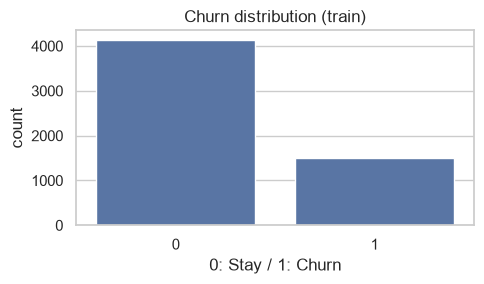

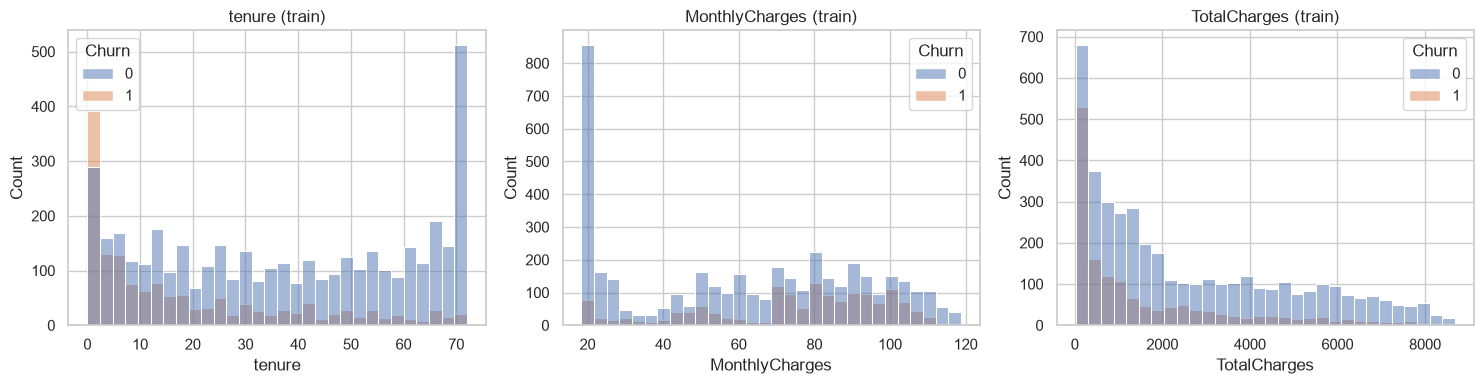

In [6]:
target_counts = eda.Churn.value_counts().sort_index()
target_table = pd.DataFrame({'고객 수': target_counts, '비율': target_counts / len(eda)})
target_table.index = ['유지 0', '이탈 1']
show_table(target_table, 'train_target_distribution')
print('전체 파일 이탈 비율:', f'{df.Churn.mean():.2%}')
print('학습 데이터 모두 유지 예측 정확도:', f'{(y_train == 0).mean():.2%}')
fig, ax = plt.subplots(figsize=(5, 3))
sns.countplot(data=eda, x='Churn', ax=ax)
ax.set(title='Churn distribution (train)', xlabel='0: Stay / 1: Churn')
show_figure('01_target_distribution', fig)
num_cols = ['tenure','MonthlyCharges','TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=eda, x=col, hue='Churn', bins=30, ax=ax)
    ax.set_title(col + ' (train)')
show_figure('02_numeric_distributions', fig)

**분포 해석:** 비이탈 고객의 비율이 약 73.46%이므로 정확도만으로 이탈 탐지 능력을 평가하기 어렵다. 정밀도·재현율·F1·ROC-AUC·AP를 함께 확인한다. 히스토그램은 고객 수 분포이며 집단별 이탈률과 구분한다.


#### 2.1.2 제거 컬럼 및 정답 분리

In [7]:
column_decisions = pd.DataFrame([
    ['customerID','입력 제외','고객 식별자이며 일반화 가능한 이용 특성이 아님'],
    ['Churn','정답 y로 분리','정답을 입력하면 데이터 누수가 발생함'],
    ['나머지 19개','초기 입력 유지','기준 성능을 확인하고 피처 실험은 학습 CV에서 비교'],
], columns=['변수','결정','이유'])
show_table(column_decisions, 'column_decisions', index=False)
assert 'customerID' not in X_train and 'Churn' not in X_train
print('현재 입력 열 수:', X_train.shape[1])

현재 입력 열 수: 19


,변수,결정,이유
0,customerID,입력 제외,고객 식별자이며 일반화 가능한 이용 특성이 아님
1,Churn,정답 y로 분리,정답을 입력하면 데이터 누수가 발생함
2,나머지 19개,초기 입력 유지,기준 성능을 확인하고 피처 실험은 학습 CV에서 비교


**변수 제외 근거:** customerID는 고객 식별자이므로 입력에서 제외한다. Churn은 정답으로 분리하고 나머지 19개를 기준 입력으로 유지한다. 중요도 그래프의 상위 10개 표시는 입력 변수를 10개로 줄였다는 뜻이 아니다.


#### 2.1.3 이탈 여부와 수치형 변수의 상관관계
Pearson은 실제 값의 선형 관계를, Spearman은 순위의 단조 관계를 요약한다. 두 방법으로 주요 수치형 변수와 이탈 여부의 연관성을 확인한다.


,Pearson,Spearman
tenure,-0.3456,-0.3599
MonthlyCharges,0.1980,0.1895
TotalCharges,-0.1948,-0.2245


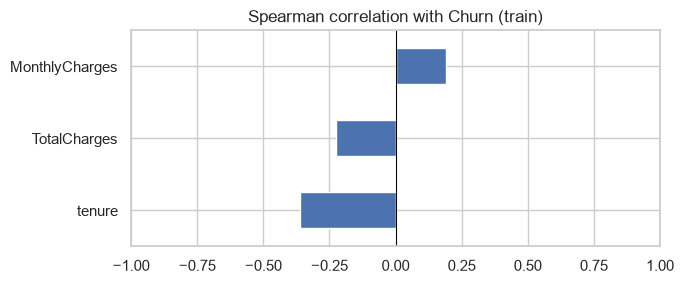

In [8]:
corr_cols = num_cols + ['Churn']
pearson = eda[corr_cols].corr(method='pearson')
spearman = eda[corr_cols].corr(method='spearman')
target_corr = pd.DataFrame({'Pearson': pearson.loc[num_cols, 'Churn'],
    'Spearman': spearman.loc[num_cols, 'Churn']})
show_table(target_corr.round(4), 'target_correlations')
fig, ax = plt.subplots(figsize=(7, 3))
target_corr['Spearman'].sort_values().plot.barh(ax=ax)
ax.axvline(0, color='black', linewidth=.7)
ax.set(title='Spearman correlation with Churn (train)', xlim=(-1, 1))
show_figure('03_target_correlations', fig)

**상관 해석:** 양수는 같은 방향, 음수는 반대 방향의 연관성을 나타낸다. 이진 타깃과의 상관은 실제 이탈 원인이나 인과효과를 의미하지 않는다. 순서가 없는 문자 범주에 임의 번호를 부여한 상관은 계산하지 않는다.


#### 2.1.4 변수 간 상관관계 히트맵

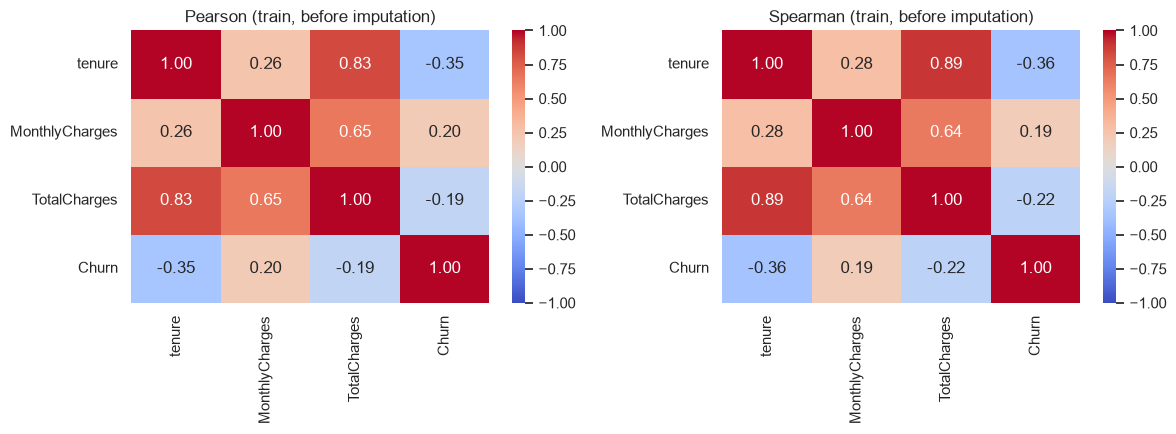

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, matrix, label in zip(axes, [pearson,spearman], ['Pearson','Spearman']):
    sns.heatmap(matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
        vmin=-1, vmax=1, ax=ax)
    ax.set_title(label + ' (train, before imputation)')
show_figure('04_correlation_heatmaps', fig)

**변수 간 관계:** 가입 기간과 누적 요금은 Pearson 약 0.83, Spearman 약 0.89로 양의 연관성을 보인다. 가입 기간이 길수록 누적 요금이 높은 경향이 있지만 고객별 월 요금은 다르다. Spearman 값이 더 높다는 사실이 분석 방법의 우월성을 의미하지는 않는다. 높은 상관만으로 변수를 자동 제거하지 않으며 제거 효과는 교차검증으로 비교한다.


#### 2.1.5 수치형 기초 통계 및 이상치 후보 확인

,count,mean,std,min,25%,50%,75%,max
tenure,5634.0,32.485091,24.568744,0.00,9.0000,29.000,55.0000,72.00
MonthlyCharges,5634.0,64.929961,30.138105,18.40,35.6625,70.500,90.0000,118.75
TotalCharges,5626.0,2302.604266,2279.173176,18.85,407.2750,1398.125,3838.6125,8684.80


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


,변수,Q1,Q3,하한,상한,IQR 범위 밖 고객 수
0,tenure,9.0000,55.0000,-60.00000,124.00000,0
1,MonthlyCharges,35.6625,90.0000,-45.84375,171.50625,0
2,TotalCharges,407.2750,3838.6125,-4739.73125,8985.61875,0


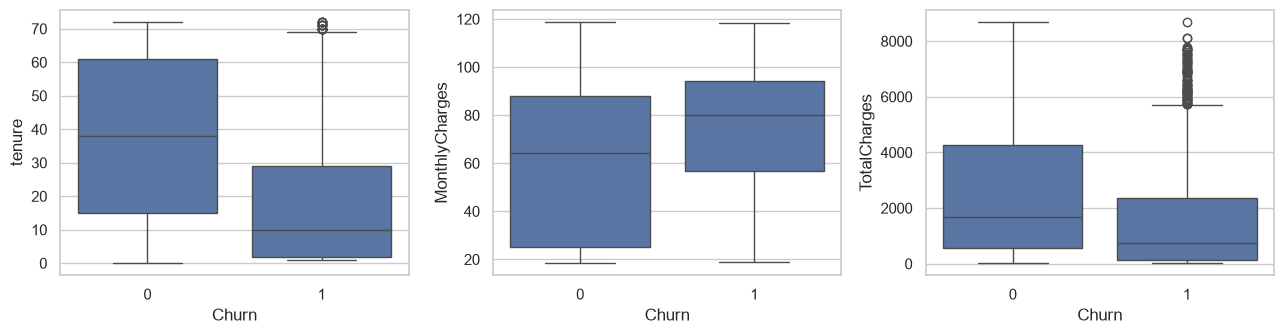

In [10]:
show_table(eda[num_cols].describe().T, 'train_numeric_profile')
show_table(df[num_cols].describe().T, 'full_file_numeric_profile')
iqr_rows = []
for col in num_cols:
    q1, q3 = X_train[col].quantile([.25,.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    mask = X_train[col].lt(lower) | X_train[col].gt(upper)
    iqr_rows.append([col, q1, q3, lower, upper, int(mask.sum())])
iqr_table = pd.DataFrame(iqr_rows, columns=['변수','Q1','Q3','하한','상한','IQR 범위 밖 고객 수'])
show_table(iqr_table, 'train_iqr_candidates', index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax,col in zip(axes,num_cols):
    sns.boxplot(data=eda, x='Churn', y=col, ax=ax)
show_figure('05_numeric_boxplots', fig)

**기초 통계와 이상치:** 평균·중앙값·범위·결측 수와 IQR 범위 밖 고객 수를 확인한다. 값이 크다는 이유로 유효 고객을 삭제하지 않는다. 학습 통계와 전체 파일 통계는 표본 수와 용도를 구분한다.

이탈 고객은 유지 고객보다 가입 기간과 누적 요금의 중앙값이 낮고 월 요금의 중앙값이 높다. 두 집단의 분포가 겹치므로 단일 변수만으로 이탈을 명확히 구분하기 어렵다. 이러한 차이는 집단 간 연관성이다.


#### 2.1.6 주요 변수 관계와 특성별 이탈률

,변수,고유 범주 수,최빈 범주,최빈 범주 고객 수
0,gender,2,Male,2833
1,SeniorCitizen,2,0,4714
2,Partner,2,No,2905
3,Dependents,2,No,3955
4,PhoneService,2,Yes,5075
5,MultipleLines,3,No,2685
6,InternetService,3,Fiber optic,2483
7,OnlineSecurity,3,No,2797
8,OnlineBackup,3,No,2442
9,DeviceProtection,3,No,2472


,Variable,Category,Customers,ChurnCount,ChurnRate
0,gender,Female,2801,746,0.266333
1,gender,Male,2833,749,0.264384
2,SeniorCitizen,0,4714,1117,0.236954
3,SeniorCitizen,1,920,378,0.410870
4,Partner,No,2905,952,0.327711
5,Partner,Yes,2729,543,0.198974
6,Dependents,No,3955,1240,0.313527
7,Dependents,Yes,1679,255,0.151876
8,PhoneService,No,559,135,0.241503
9,PhoneService,Yes,5075,1360,0.267980


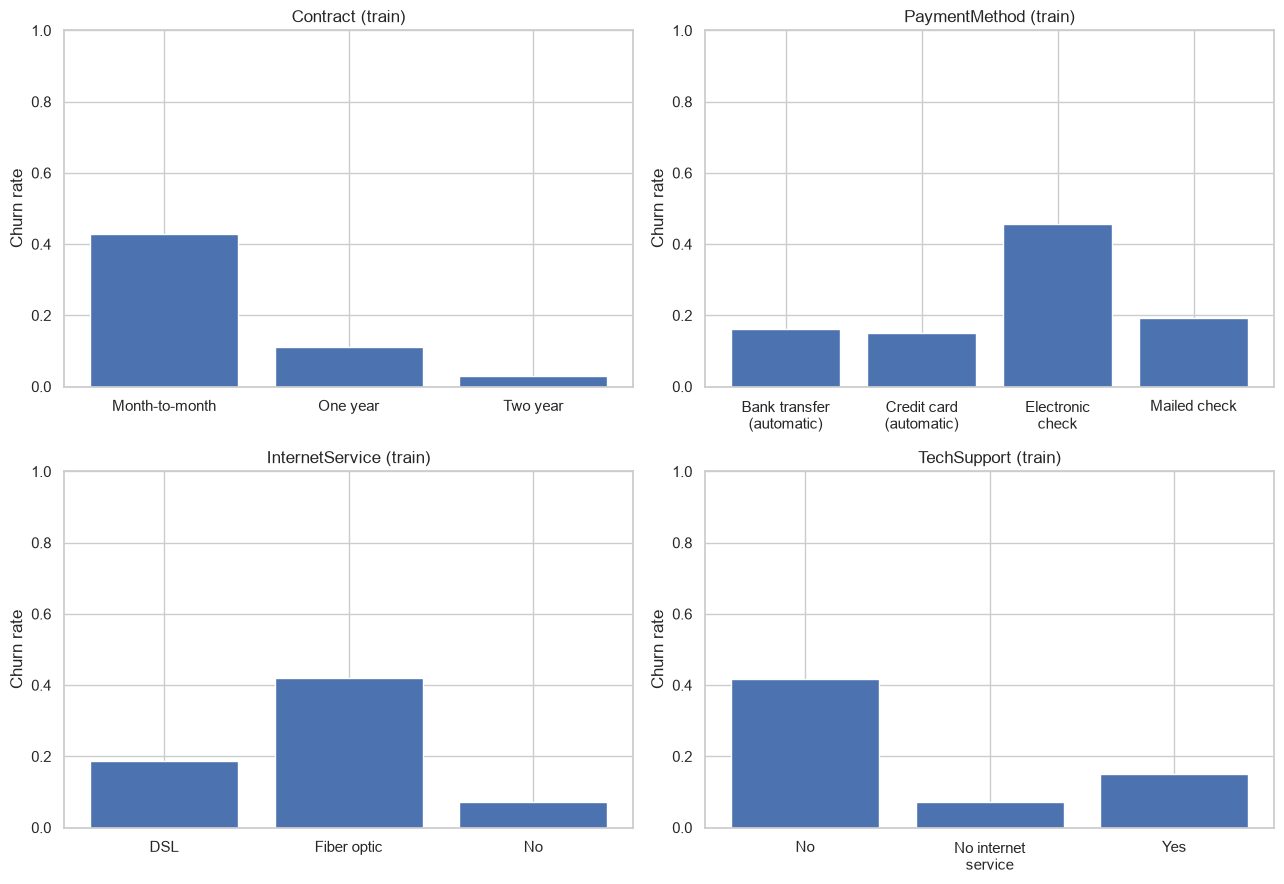

,Customers,ChurnCount,ChurnRate
tenure,,,
0-12,1737,822,0.473230
13-24,818,234,0.286064
25-36,669,140,0.209268
37-48,621,121,0.194847
49-60,658,101,0.153495
61-72,1131,77,0.068081


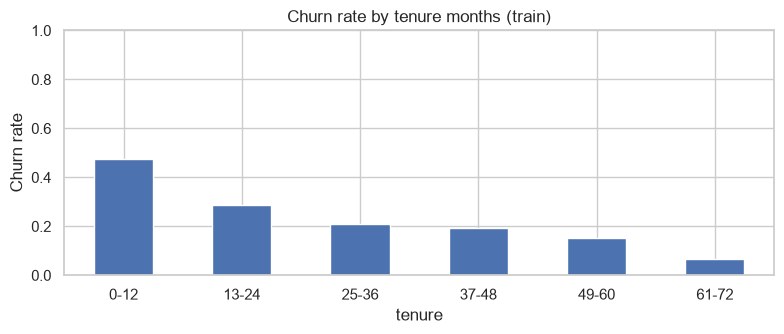

In [11]:
category_cols = X_train.select_dtypes(exclude='number').columns.tolist()
category_profile = pd.DataFrame([
    [col, X_train[col].nunique(dropna=False), X_train[col].mode().iloc[0],
     X_train[col].value_counts(dropna=False).iloc[0]] for col in category_cols
], columns=['변수','고유 범주 수','최빈 범주','최빈 범주 고객 수'])
show_table(category_profile, 'train_category_profile', index=False)
category_rate_tables = []
for col in category_cols:
    rates = eda.groupby(col, observed=True, dropna=False)['Churn'].agg(
        Customers='size', ChurnCount='sum', ChurnRate='mean').reset_index()
    rates = rates.rename(columns={col:'Category'})
    rates.insert(0,'Variable',col)
    category_rate_tables.append(rates)
all_category_rates = pd.concat(category_rate_tables,ignore_index=True)
show_table(all_category_rates, 'all_category_churn_rates', index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax,col in zip(axes.ravel(),['Contract','PaymentMethod','InternetService','TechSupport']):
    rates = all_category_rates.loc[all_category_rates.Variable.eq(col)]
    ax.bar(range(len(rates)), rates.ChurnRate)
    ax.set_xticks(range(len(rates)), [textwrap.fill(str(v),15) for v in rates.Category])
    ax.set(title=col+' (train)',ylabel='Churn rate',ylim=(0,1))
show_figure('06_category_churn_rates', fig)

tenure_group = pd.cut(eda.tenure, [-1,12,24,36,48,60,72],
    labels=['0-12','13-24','25-36','37-48','49-60','61-72'])
tenure_rates = eda.groupby(tenure_group,observed=True)['Churn'].agg(
    Customers='size',ChurnCount='sum',ChurnRate='mean')
show_table(tenure_rates, 'tenure_churn_rates')
fig,ax=plt.subplots(figsize=(8,3.5))
tenure_rates.ChurnRate.plot.bar(ax=ax,rot=0,ylim=(0,1))
ax.set(title='Churn rate by tenure months (train)',ylabel='Churn rate')
show_figure('07_tenure_churn_rates',fig)

**범주별 이탈률:** 각 막대는 해당 범주의 이탈 고객 수를 해당 범주의 전체 고객 수로 나눈 비율이다. Churn이 0/1이므로 집단별 평균은 이탈률과 같다. 표에는 고객 수·이탈 고객 수·이탈률을 함께 표시한다.

Contract는 계약 유형, PaymentMethod는 결제 방식, InternetService는 인터넷 종류, TechSupport는 기술 지원 이용 상태별 비교다. 월 단위 계약·전자수표·광인터넷 이용 집단과 인터넷 가입 상태에서 기술 지원을 이용하지 않는 집단에서 상대적으로 높은 이탈률이 관찰된다.

가입 기간 그래프는 서로 다른 고객 집단의 비교이며 동일 고객의 시간별 변화가 아니다. 계약 변경이나 기술 지원 가입의 이탈 감소 효과를 검증한 결과도 아니다.


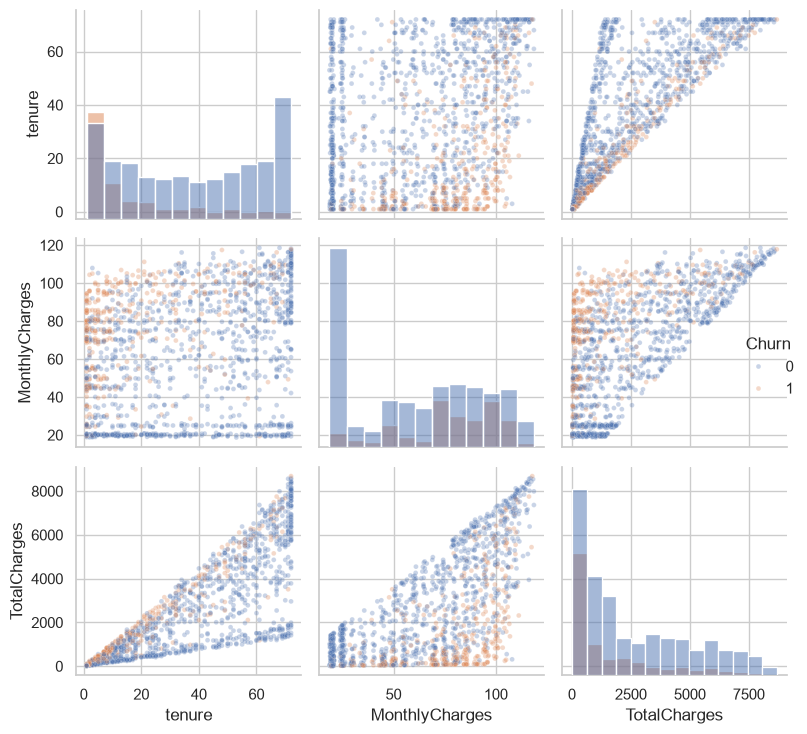

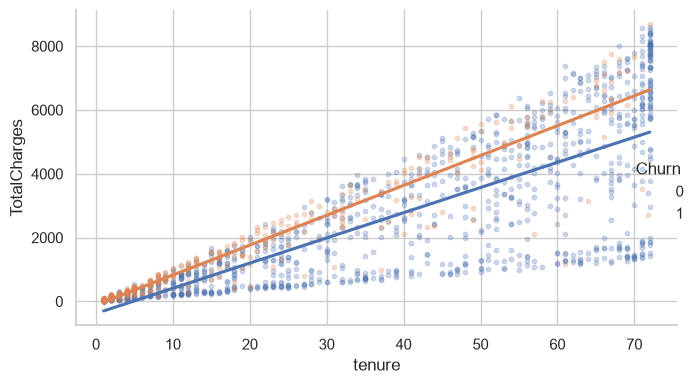

In [12]:
plot_data=eda[num_cols+['Churn']].dropna()
plot_data=plot_data.sample(n=min(1500,len(plot_data)),random_state=SEED)
pair=sns.pairplot(plot_data,hue='Churn',diag_kind='hist',plot_kws={'s':12,'alpha':.3})
show_figure('08_pairplot',pair.fig)
trend=sns.lmplot(data=plot_data,x='tenure',y='TotalCharges',hue='Churn',
    height=4,aspect=1.6,ci=None,scatter_kws={'s':10,'alpha':.25})
show_figure('09_tenure_charge_trend',trend.fig)

**수치형 변수 관계:** Pairplot의 대각선은 변수별 분포, 나머지는 두 변수의 산점도다. 점 하나는 고객 한 명이고 색은 이탈 여부다. 결측이 없는 학습 고객 중 최대 1,500명을 고정 난수로 추출하여 시각화한다. 모델 학습 표본 수를 줄이는 과정은 아니다.

가입 기간과 누적 요금은 증가 관계를 보이지만 이탈·유지 집단의 분포가 겹친다. lmplot은 이 관계에 집단별 선형 추세선을 추가한 보충 그림이다. 추세선은 이탈 확률 예측선이나 실제 월 요금이 아니다.

### 2.2 데이터 전처리
#### 2.2.1 결측치 및 이상치 처리와 파생변수 설계
수치형 결측은 극단값의 영향을 평균보다 덜 받는 중앙값으로, 범주형 결측은 최빈값으로 대체한다. 전처리를 동일하게 유지하여 모델을 비교하며, 이 대체 방식이 최적이라고 검증한 것은 아니다.


In [13]:
treatment_table=pd.DataFrame([
    ['customerID','입력 제외','식별자'],
    ['Churn','Yes=1, No=0으로 변환 후 정답 분리','이진 분류'],
    ['TotalCharges','숫자 변환 후 학습 폴드 중앙값 대체','전체 공백 11건 · 학습 결측 '+str(X_train.TotalCharges.isna().sum())+'건'],
    ['SeniorCitizen','0/1을 범주형 문자열로 처리','연속 수치가 아닌 고객 범주'],
    ['서비스 미이용 범주','No internet/phone service 유지','일반 결측이 아닌 실제 서비스 상태'],
    ['수치형','학습 폴드의 중앙값 대체·표준화','트리에는 필수 아님 · 로지스틱 회귀와 동일 구조'],
    ['범주형','학습 폴드 최빈값 대체·원핫 인코딩','문자 범주를 모델 입력으로 변환'],
    ['이상치 후보','이번 분석에서는 별도 행 삭제 없음','기초 통계와 IQR 후보를 확인'],
],columns=['대상','처리','이유 또는 확인 결과'])
show_table(treatment_table,'preprocessing_decisions',index=False)

,대상,처리,이유 또는 확인 결과
0,customerID,입력 제외,식별자
1,Churn,"Yes=1, No=0으로 변환 후 정답 분리",이진 분류
2,TotalCharges,숫자 변환 후 학습 폴드 중앙값 대체,전체 공백 11건 · 학습 결측 8건
3,SeniorCitizen,0/1을 범주형 문자열로 처리,연속 수치가 아닌 고객 범주
4,서비스 미이용 범주,No internet/phone service 유지,일반 결측이 아닌 실제 서비스 상태
5,수치형,학습 폴드의 중앙값 대체·표준화,트리에는 필수 아님 · 로지스틱 회귀와 동일 구조
6,범주형,학습 폴드 최빈값 대체·원핫 인코딩,문자 범주를 모델 입력으로 변환
7,이상치 후보,이번 분석에서는 별도 행 삭제 없음,기초 통계와 IQR 후보를 확인


In [14]:
def make_features(X, variant='original'):
    """Row-wise formulas use neither targets nor dataset statistics."""
    result = X.copy()
    if variant == 'drop_phone':
        return result.drop(columns='PhoneService')
    allowed = ['original', 'tenure_band', 'average_charge', 'charge_gap', 'engineered']
    if variant not in allowed:
        raise ValueError(variant)
    if variant in ['tenure_band', 'engineered']:
        result['TenureBand'] = pd.cut(result['tenure'], [-1, 12, 24, 48, np.inf],
            labels=['0-12', '13-24', '25-48', '49+']).astype(str)
    average = result['TotalCharges'].div(result['tenure'].replace(0, np.nan))
    if variant in ['average_charge', 'engineered']:
        result['AvgChargePerMonth'] = average
    if variant in ['charge_gap', 'engineered']:
        result['ChargeGap'] = result['MonthlyCharges'] - average
    return result

def make_preprocessor(X):
    numerical = X.select_dtypes(include='number').columns.tolist()
    categorical = X.columns.difference(numerical).tolist()
    return ColumnTransformer([
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())]), numerical),
        ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))]), categorical)])

def make_pipeline(X, model):
    return Pipeline([('preprocessor', make_preprocessor(X)), ('model', model)])

def xgb_model(**settings):
    params = dict(n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, objective='binary:logistic',
        eval_metric='logloss', tree_method='hist', importance_type='gain',
        random_state=SEED, n_jobs=2)
    params.update(settings)
    return XGBClassifier(**params)

def baseline_models():
    return {'LogisticRegression': LogisticRegression(max_iter=2000),
        'RandomForest': RandomForestClassifier(n_estimators=300, max_depth=8,
            min_samples_leaf=5, random_state=SEED, n_jobs=2),
        'XGBoost': xgb_model()}

def metric_scores(y, probabilities):
    predicted = (np.asarray(probabilities) >= 0.5).astype(int)
    return dict(Accuracy=accuracy_score(y, predicted),
        Precision=precision_score(y, predicted, zero_division=0),
        Recall=recall_score(y, predicted, zero_division=0),
        F1=f1_score(y, predicted, zero_division=0),
        **{'ROC-AUC': roc_auc_score(y, probabilities),
           'AP': average_precision_score(y, probabilities)})

**전처리 구조:** `make_features`는 행별 계산 또는 열 제거, `make_preprocessor`는 열 유형별 처리, `make_pipeline`은 전처리와 모델의 연결, `metric_scores`는 지표 계산을 담당한다.

`drop='first'`는 기준 범주 하나를 제외한다. `handle_unknown='ignore'`는 미관측 범주에서 변환 오류를 막지만 예측 신뢰도를 보장하지 않는다.

#### 2.2.2 전처리 결과 및 입력 피처 확인
아래 전처리 객체는 학습 데이터 확인용이다. 교차검증에서는 새 Pipeline을 각 폴드에서 따로 fit한다.


In [15]:
preview_preprocessor=make_preprocessor(X_train)
preview_preprocessor.fit(X_train)
feature_names=preview_preprocessor.get_feature_names_out()
numeric_columns=X_train.select_dtypes(include='number').columns.tolist()
categorical_columns=X_train.columns.difference(numeric_columns).tolist()
preprocess_summary=pd.DataFrame([
    ['전체 고객 수',len(raw),len(df)],
    ['데이터 열 수',raw.shape[1],df.shape[1]],
    ['입력 변수 수','식별자·정답 분리 전',X_train.shape[1]],
    ['수치형 입력 수','의미·자료형 확인',len(numeric_columns)],
    ['범주형 입력 수','SeniorCitizen 포함',len(categorical_columns)],
    ['인코딩 이후 피처 수','원본 입력 '+str(X_train.shape[1]),len(feature_names)],
],columns=['항목','전 또는 기준','후 또는 결과'])
show_table(preprocess_summary,'preprocessing_summary',index=False)
show_table(pd.Series(feature_names,name='변환 후 피처명').to_frame(),'encoded_feature_names',index=False)
transformed=preview_preprocessor.transform(X_train.head())
if hasattr(transformed,'toarray'):transformed=transformed.toarray()
assert np.isfinite(transformed).all()
show_table(pd.DataFrame(transformed,columns=feature_names,index=X_train.head().index),
    'transformed_sample')
median_values=pd.Series(preview_preprocessor.named_transformers_['numeric'].named_steps['imputer'].statistics_,
    index=numeric_columns,name='학습 80% 중앙값')
show_table(median_values.to_frame(),'preview_training_medians')

,항목,전 또는 기준,후 또는 결과
0,전체 고객 수,7043,7043
1,데이터 열 수,21,20
2,입력 변수 수,식별자·정답 분리 전,19
3,수치형 입력 수,의미·자료형 확인,3
4,범주형 입력 수,SeniorCitizen 포함,16
5,인코딩 이후 피처 수,원본 입력 19,30


,변환 후 피처명
0,numeric__tenure
1,numeric__MonthlyCharges
2,numeric__TotalCharges
3,categorical__Contract_One year
4,categorical__Contract_Two year
5,categorical__Dependents_Yes
6,categorical__DeviceProtection_No internet service
7,categorical__DeviceProtection_Yes
8,categorical__InternetService_Fiber optic
9,categorical__InternetService_No


,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,categorical__Contract_One year,categorical__Contract_Two year,categorical__Dependents_Yes,categorical__DeviceProtection_No internet service,categorical__DeviceProtection_Yes,categorical__InternetService_Fiber optic,categorical__InternetService_No,categorical__MultipleLines_No phone service,categorical__MultipleLines_Yes,categorical__OnlineBackup_No internet service,categorical__OnlineBackup_Yes,categorical__OnlineSecurity_No internet service,categorical__OnlineSecurity_Yes,categorical__PaperlessBilling_Yes,categorical__Partner_Yes,categorical__PaymentMethod_Credit card (automatic),categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check,categorical__PhoneService_Yes,categorical__SeniorCitizen_1,categorical__StreamingMovies_No internet service,categorical__StreamingMovies_Yes,categorical__StreamingTV_No internet service,categorical__StreamingTV_Yes,categorical__TechSupport_No internet service,categorical__TechSupport_Yes,categorical__gender_Male
3738,0.102371,-0.521976,-0.263290,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
3151,-0.711743,0.337478,-0.504815,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4860,-0.793155,-0.809013,-0.751214,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
3867,-0.263980,0.284384,-0.173700,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3810,-1.281624,-0.676279,-0.990851,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


,학습 80% 중앙값
tenure,29.000
MonthlyCharges,70.500
TotalCharges,1398.125


**변환 결과:** 전체 21열에서 식별자와 정답을 분리하면 입력 19개이며, 원핫 인코딩 후 30개 피처로 변환된다. 고객 수는 유지된다. 표준화 후 음수는 학습 평균보다 낮은 값이라는 뜻이며 원래 요금이 음수라는 뜻이 아니다.


#### 2.2.3 전처리 전후 관계 확인

,대체 전 결측,대체 후 결측
tenure,0,0
MonthlyCharges,0,0
TotalCharges,8,0


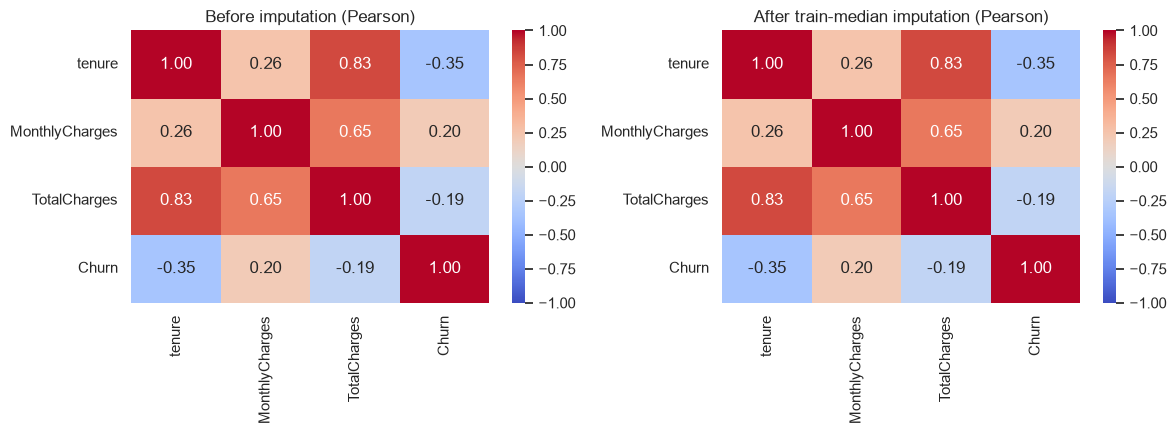

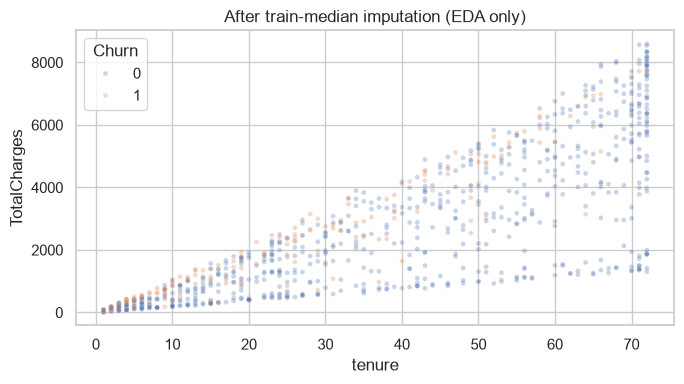

In [16]:
clean_eda=eda.copy()
clean_eda[num_cols]=SimpleImputer(strategy='median').fit_transform(eda[num_cols])
before_after=pd.DataFrame({'대체 전 결측':eda[num_cols].isna().sum(),
    '대체 후 결측':clean_eda[num_cols].isna().sum()})
show_table(before_after,'missing_before_after')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,data,title in zip(axes,[eda,clean_eda],['Before imputation','After train-median imputation']):
    sns.heatmap(data[corr_cols].corr(),annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1,ax=ax)
    ax.set_title(title+' (Pearson)')
show_figure('10_before_after_heatmaps',fig)
fig,ax=plt.subplots(figsize=(7,4))
sample=clean_eda.sample(n=min(1000,len(clean_eda)),random_state=SEED)
sns.scatterplot(data=sample,x='tenure',y='TotalCharges',hue='Churn',alpha=.3,s=12,ax=ax)
ax.set_title('After train-median imputation (EDA only)')
show_figure('11_after_imputation_scatter',fig)

**결측 대체 전후:** 학습 데이터의 누적 요금 결측은 8건으로 약 0.14%다. 중앙값 대체 후 수치형 결측은 0건이며, Pearson 상관계수는 소수 둘째 자리 표시에서 큰 차이가 없다. 결측 비중이 작아 영향이 제한적이었을 가능성이 있으며 표시값이 같아도 계산값이 완전히 같은 것은 아니다.

이 그림의 대체 데이터는 EDA용이다. 실제 교차검증에서는 각 학습 폴드의 전처리 객체로 대체값을 구한다. 결측 대체의 목적은 결측 고객도 모델 입력으로 사용할 수 있도록 하는 것이다.


In [17]:
def cv_experiment(X, y, model, with_importance=False):
    """Each row is predicted by a fold model that did not train on it."""
    folds = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    oof = np.full(len(y), np.nan)
    fold_auc, importances = [], []
    for train_idx, val_idx in folds.split(X, y):
        pipeline = make_pipeline(X.iloc[train_idx], clone(model))
        pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])
        probability = pipeline.predict_proba(X.iloc[val_idx])[:, 1]
        oof[val_idx] = probability
        fold_auc.append(roc_auc_score(y.iloc[val_idx], probability))
        if with_importance:
            imp = permutation_importance(pipeline, X.iloc[val_idx], y.iloc[val_idx],
                scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=1)
            importances.append(imp.importances)
    assert np.isfinite(oof).all()
    scores = metric_scores(y, oof)
    scores['CV_AUC_mean'] = float(np.mean(fold_auc))
    scores['CV_AUC_std'] = float(np.std(fold_auc))
    frame = None
    if importances:
        values = np.concatenate(importances, axis=1)
        frame = pd.DataFrame({'Feature': X.columns, 'Mean': values.mean(axis=1),
            'Std': values.std(axis=1)}).sort_values('Mean', ascending=False)
    return scores, oof, frame

### 3.2 예측 모델 구성 및 비교
#### 3.2.1 베이스라인 모델 비교
- Logistic Regression: 입력의 선형 결합을 사용해 이탈 확률을 추정하는 분류 기준 모델.
- Random Forest: 여러 의사결정나무의 예측을 결합하여 비선형 관계와 상호작용을 학습하는 모델.
- XGBoost: 앞선 예측의 오차를 보완하는 방향으로 나무를 순차 추가하는 부스팅 모델.

세 모델을 동일한 분할·전처리·평가 조건에서 비교한다.


CV: LogisticRegression
CV: RandomForest
CV: XGBoost
CV: XGB_drop_PhoneService
CV: XGB_engineered
CV: XGB_depth2_trees150
CV: XGB_depth2_trees300
CV: XGB_depth3_trees150
CV: XGB_tenure_band
CV: XGB_average_charge
CV: XGB_charge_gap
CV: RF_balanced


,모델,적용 목적,설정
0,LogisticRegression,선형 분류 기준,max_iter=2000
1,RandomForest,트리 앙상블 비교,"300개, max_depth=8, min_samples_leaf=5"
2,XGBoost,부스팅 분류 비교,"300개, max_depth=3, learning_rate=0.05, subsamp..."


,Variant,Accuracy,Precision,Recall,F1,ROC-AUC,AP,CV_AUC_mean,CV_AUC_std
Model,,,,,,,,,
LogisticRegression,original,0.8030,0.6554,0.5431,0.5940,0.8454,0.6578,0.8458,0.0076
RandomForest,original,0.8001,0.6749,0.4763,0.5584,0.8461,0.6585,0.8469,0.0098
XGBoost,original,0.8009,0.6574,0.5211,0.5813,0.8456,0.6610,0.8464,0.0082


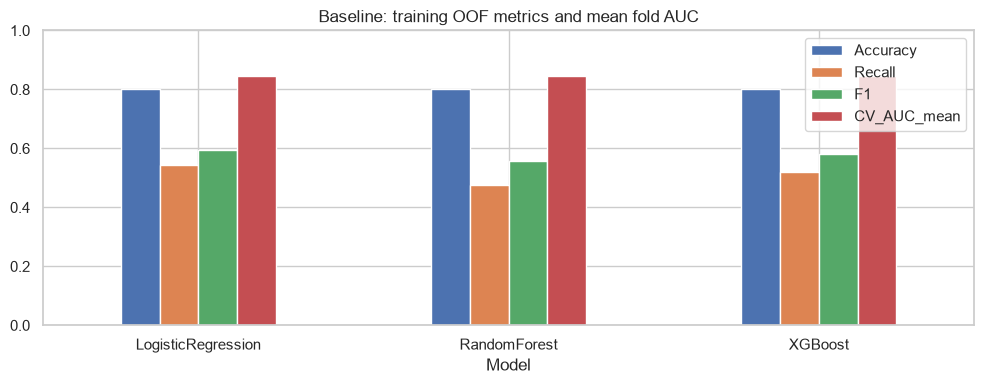

In [18]:
def compare_candidates(X_train, y_train, out):
    """No test data is passed to this function."""
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    specs = {name: ('original', model) for name, model in baseline_models().items()}
    # Fixed hypotheses from the earlier report; not chosen on test results.
    specs['XGB_drop_PhoneService'] = ('drop_phone', xgb_model())
    specs['XGB_engineered'] = ('engineered', xgb_model())
    for depth in [2, 3]:
        for trees in [150, 300]:
            if depth == 3 and trees == 300:
                continue  # Same settings as baseline: reuse its CV score.
            specs[f'XGB_depth{depth}_trees{trees}'] = ('original', xgb_model(max_depth=depth, n_estimators=trees))
    # 한 번에 하나씩 바꿔야 어떤 변경의 결과인지 설명하기 쉽습니다.
    for variant in ['tenure_band', 'average_charge', 'charge_gap']:
        specs['XGB_' + variant] = (variant, xgb_model())
    specs['RF_balanced'] = ('original', RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=5,
        class_weight='balanced', random_state=SEED, n_jobs=2))
    rows, predictions, importance = [], {}, None
    for name, (variant, model) in specs.items():
        print(f'CV: {name}', flush=True)
        scores, oof, frame = cv_experiment(make_features(X_train, variant), y_train,
            model, with_importance=(name == 'XGBoost'))
        rows.append(dict(Model=name, Variant=variant, **scores))
        predictions[name] = oof
        if frame is not None:
            importance = frame
    table = pd.DataFrame(rows).set_index('Model').sort_values('CV_AUC_mean', ascending=False, kind='stable')
    table.to_csv(out / 'cv_comparison.csv', encoding='utf-8-sig')
    importance.to_csv(out / 'cv_permutation_importance.csv', index=False, encoding='utf-8-sig')
    pd.DataFrame(predictions, index=X_train.index).to_csv(out / 'cv_oof_predictions.csv')
    return specs, table, importance
specs,cv_table,permutation=compare_candidates(X_train,y_train,OUT)
baseline_names=list(baseline_models())
baseline_settings=pd.DataFrame([
    ['LogisticRegression','선형 분류 기준','max_iter=2000'],
    ['RandomForest','트리 앙상블 비교','300개, max_depth=8, min_samples_leaf=5'],
    ['XGBoost','부스팅 분류 비교','300개, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8'],
],columns=['모델','적용 목적','설정'])
show_table(baseline_settings,'baseline_settings',index=False)
show_table(cv_table.loc[baseline_names].round(4),'baseline_cv_scores')
fig,ax=plt.subplots(figsize=(10,4))
cv_table.loc[baseline_names,['Accuracy','Recall','F1','CV_AUC_mean']].plot.bar(ax=ax,rot=0,ylim=(0,1))
ax.set_title('Baseline: training OOF metrics and mean fold AUC')
show_figure('12_baseline_cv_comparison',fig)

**기준 모델 결과:** 평균 CV ROC-AUC는 랜덤 포레스트 0.8469, XGBoost 0.8464, 로지스틱 회귀 0.8458이다. AUC가 높은 모델과 재현율·F1이 높은 모델은 다를 수 있다. 표의 정밀도·재현율·F1은 OOF 예측을 모아 계산하고, CV AUC는 폴드별 AUC의 평균을 사용한다.


#### 3.2.2 학습 및 교차검증 성능 차이 점검
아래는 학습 80% 전체에 맞춘 모델의 학습 점수와 학습 내부 CV 점수를 비교한다. 테스트는 사용하지 않는다. 실제 학습 표본 수가 달라 엄밀히 동일한 모델의 일반화 격차는 아니다. 과적합 징후를 살펴보는 보조 자료다.

,Train Accuracy,OOF Accuracy,Train AUC,CV mean AUC,AUC gap
Model,,,,,
LogisticRegression,0.8055,0.8030,0.8492,0.8458,0.0034
RandomForest,0.8252,0.8001,0.8891,0.8469,0.0422
XGBoost,0.8237,0.8009,0.8843,0.8464,0.0378


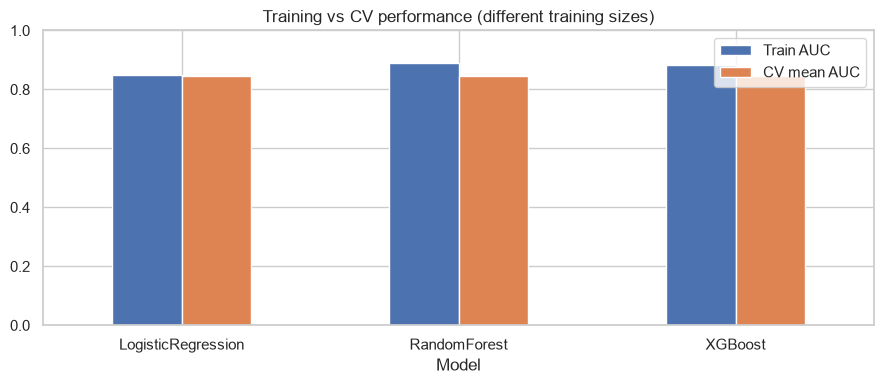

In [19]:
gap_rows=[]
for name in baseline_names:
    pipe=make_pipeline(X_train,clone(specs[name][1])).fit(X_train,y_train)
    train_score=metric_scores(y_train,pipe.predict_proba(X_train)[:,1])
    gap_rows.append([name,train_score['Accuracy'],cv_table.loc[name,'Accuracy'],
        train_score['ROC-AUC'],cv_table.loc[name,'CV_AUC_mean'],
        train_score['ROC-AUC']-cv_table.loc[name,'CV_AUC_mean']])
gap_table=pd.DataFrame(gap_rows,columns=['Model','Train Accuracy','OOF Accuracy',
    'Train AUC','CV mean AUC','AUC gap']).set_index('Model')
show_table(gap_table.round(4),'training_cv_gap')
fig,ax=plt.subplots(figsize=(9,4))
gap_table[['Train AUC','CV mean AUC']].plot.bar(ax=ax,rot=0,ylim=(0,1))
ax.set_title('Training vs CV performance (different training sizes)')
show_figure('13_training_cv_gap',fig)

**학습·검증 차이:** 학습 AUC와 CV AUC의 차이를 통해 학습 데이터에 과도하게 맞춘 징후를 살펴본다. 전체 학습과 각 CV 폴드의 실제 학습 표본 수가 다르므로 동일한 모델의 엄밀한 일반화 격차로 해석하거나 과적합을 확정하지 않는다.


#### 3.2.3 하이퍼파라미터 탐색 및 피처 개선
1차 실험은 깊이 2·3과 나무 150·300의 4조합 수동 전수 비교다. 추가 실험에서는 파생변수를 하나씩 추가한 경우, 세 변수를 함께 추가한 경우, PhoneService 제거, 클래스 가중치, GridSearchCV 튜닝을 비교한다. 모든 선택은 학습 내부의 동일한 3겹 CV로 수행한다.


##### 가. 파생변수 및 클래스 가중치 실험
한 번에 하나의 변경을 비교하여 변경 효과를 구분한다.

| 실험 | 변경 내용과 목적 |
|---|---|
| 가입 기간 구간 | 초기·장기 고객 차이를 구간 범주로 표현 |
| 월평균 누적 요금 | TotalCharges / tenure로 고객별 평균 요금 수준 표현 |
| 요금 차이 | 현재 월 요금 − 월평균 누적 요금 |
| 세 파생변수 함께 | 개별 추가와 통합 추가 효과 비교 |
| 클래스 가중치 | RF에 balanced를 적용하여 적은 클래스의 학습 가중치 증가 |

0개월 고객은 나누지 않고 결측으로 두며 각 학습 폴드에서 대체한다. 요금 차이는 실제 요금 인상 이력이 아니다. 정답 Churn은 파생변수 계산에 사용하지 않는다.

불균형 처리는 가상 고객을 만드는 SMOTE 대신 클래스 가중치로 비교한다. 범주형이 많은 데이터에 일반 SMOTE를 그대로 적용하면 원핫 값 사이의 중간값이 생길 수 있기 때문이다. 가중치는 각 fit의 학습 정답 비율로 구하며 검증·테스트 고객의 분포는 바꾸지 않는다.


##### 나. GridSearchCV 자동 탐색
전처리와 모델을 하나의 Pipeline으로 묶어 RF 8조합, XGBoost 16조합을 계층 3겹 교차검증으로 비교한다. 선택 기준은 평균 ROC-AUC이며 재현율과 F1도 기록한다.

| 설정 | 의미 |
|---|---|
| n_estimators | 나무 개수 |
| max_depth | 나무의 최대 깊이 |
| min_samples_leaf | RF 잎 하나에 필요한 최소 고객 수 |
| learning_rate | XGBoost 나무 한 개의 반영 정도 |
| reg_lambda | XGBoost 잎 점수의 크기를 억제하는 L2 규제 |

`model__`은 Pipeline의 model 단계 설정을 뜻한다. 중앙값·인코딩·표준화는 매 학습 폴드 안에서 학습된다. 나무 수·깊이를 늘리거나 규제를 강화하는 것이 항상 성능 향상을 보장하지는 않는다.


In [20]:
# 1. 후보 범위를 미리 정합니다. 테스트 결과를 보고 범위를 수정하지 않습니다.
search_spaces = {
    'RF_GridSearch': (baseline_models()['RandomForest'], {
        'model__n_estimators': [150, 300],
        'model__max_depth': [4, 8],
        'model__min_samples_leaf': [2, 5],
    }),
    'XGB_GridSearch': (xgb_model(), {
        'model__n_estimators': [150, 300],
        'model__max_depth': [2, 3],
        'model__learning_rate': [0.03, 0.05],
        'model__reg_lambda': [1, 5],
    }),
}
searches = {}
tuning_results = {}
for name, (base_model, param_grid) in search_spaces.items():
    print('자동 튜닝:', name, flush=True)
    # 2. 원본 학습 80%만 전달합니다. 전처리도 fold 안에서 fit합니다.
    search = GridSearchCV(
        estimator=make_pipeline(X_train, clone(base_model)),
        param_grid=param_grid,
        scoring={'AUC': 'roc_auc', 'Recall': 'recall', 'F1': 'f1'},
        refit='AUC',
        cv=StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED),
        n_jobs=1, error_score='raise', return_train_score=True,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    # 3. 가장 좋은 설정의 모델을 기존 후보 목록에 추가합니다.
    best_model = clone(search.best_estimator_.named_steps['model'])
    specs[name] = ('original', best_model)
    scores, oof, _ = cv_experiment(X_train, y_train, best_model)
    np.testing.assert_allclose(scores['CV_AUC_mean'], search.best_score_, atol=1e-12)
    cv_table.loc[name] = {'Variant': 'original', **scores}
    oof_table = pd.read_csv(OUT/'cv_oof_predictions.csv', index_col=0)
    np.testing.assert_array_equal(oof_table.index, X_train.index)
    oof_table[name] = oof
    oof_table.to_csv(OUT/'cv_oof_predictions.csv')
    details = pd.DataFrame(search.cv_results_)
    cols = ['params', 'mean_test_AUC', 'std_test_AUC', 'mean_test_Recall',
            'mean_test_F1', 'mean_train_AUC', 'rank_test_AUC']
    tuning_results[name] = details[cols].sort_values('rank_test_AUC')
    display(tuning_results[name].round(4))
    print('선택한 설정:', search.best_params_)
    print('최고 평균 CV AUC:', round(search.best_score_, 4))
cv_table = cv_table.sort_values('CV_AUC_mean', ascending=False, kind='stable')
# 기존 CV 결과 파일에 추가 후보도 반영합니다.
cv_table.to_csv(OUT/'cv_comparison.csv', encoding='utf-8-sig')


자동 튜닝: RF_GridSearch
선택한 설정: {'model__max_depth': 8, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
최고 평균 CV AUC: 0.8469
자동 튜닝: XGB_GridSearch
선택한 설정: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__reg_lambda': 5}
최고 평균 CV AUC: 0.8503


,params,mean_test_AUC,std_test_AUC,mean_test_Recall,mean_test_F1,mean_train_AUC,rank_test_AUC
7,"{'model__max_depth': 8, 'model__min_samples_le...",0.8469,0.0098,0.4763,0.5582,0.8982,1
6,"{'model__max_depth': 8, 'model__min_samples_le...",0.8466,0.0098,0.4789,0.5609,0.8981,2
5,"{'model__max_depth': 8, 'model__min_samples_le...",0.8465,0.0100,0.4763,0.5591,0.9104,3
4,"{'model__max_depth': 8, 'model__min_samples_le...",0.8460,0.0096,0.4803,0.5619,0.9103,4
0,"{'model__max_depth': 4, 'model__min_samples_le...",0.8420,0.0088,0.3887,0.4971,0.8525,5
1,"{'model__max_depth': 4, 'model__min_samples_le...",0.8418,0.0084,0.3786,0.4900,0.8527,6
2,"{'model__max_depth': 4, 'model__min_samples_le...",0.8418,0.0087,0.3887,0.4973,0.8520,7
3,"{'model__max_depth': 4, 'model__min_samples_le...",0.8417,0.0083,0.3786,0.4900,0.8523,8


,params,mean_test_AUC,std_test_AUC,mean_test_Recall,mean_test_F1,mean_train_AUC,rank_test_AUC
3,"{'model__learning_rate': 0.03, 'model__max_dep...",0.8503,0.0105,0.5251,0.5925,0.8632,1
2,"{'model__learning_rate': 0.03, 'model__max_dep...",0.8500,0.0103,0.5231,0.5911,0.8646,2
12,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8497,0.0092,0.5197,0.5841,0.8771,3
8,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8496,0.0102,0.5151,0.5858,0.8627,4
11,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8496,0.0097,0.5345,0.5952,0.8694,5
13,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8495,0.0094,0.5264,0.5899,0.8736,6
7,"{'model__learning_rate': 0.03, 'model__max_dep...",0.8494,0.0093,0.5264,0.5894,0.8770,7
10,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8493,0.0088,0.5338,0.5941,0.8718,8
9,"{'model__learning_rate': 0.05, 'model__max_dep...",0.8493,0.0110,0.5184,0.5872,0.8615,9
5,"{'model__learning_rate': 0.03, 'model__max_dep...",0.8491,0.0105,0.5044,0.5803,0.8660,10


##### 다. 개선 전후 비교
RF 변경은 기준 RF와, XGBoost 변경은 기준 XGBoost와 비교한다. AUC_change는 평균 CV AUC 차이이며, Recall_change와 F1_change는 OOF 지표의 차이다. 양수는 증가, 음수는 감소다.

GridSearchCV의 재현율·F1은 폴드 점수 평균이고 아래 표는 OOF 예측을 모은 값이므로 조금 다를 수 있다. AUC는 모두 폴드별 점수 평균이다. 탐색과 선택에 같은 CV를 사용하여 최고점에 선택 편향이 있을 수 있으며, 작은 차이는 통계적 우월성을 입증하지 않는다.


가입 기간 구간 추가: AUC 0.8464 → 0.8461 (-0.0004), Recall 변화 -0.0007, F1 변화 -0.0005
월평균 누적 요금 추가: AUC 0.8464 → 0.8461 (-0.0003), Recall 변화 +0.0007, F1 변화 -0.0016
현재와 평균 요금 차이 추가: AUC 0.8464 → 0.8450 (-0.0014), Recall 변화 +0.0013, F1 변화 +0.0037
세 파생변수 함께 추가: AUC 0.8464 → 0.8448 (-0.0016), Recall 변화 -0.0074, F1 변화 -0.0030
전화 가입 변수 제거: AUC 0.8464 → 0.8466 (+0.0002), Recall 변화 -0.0013, F1 변화 -0.0028
클래스 가중치 적용: AUC 0.8469 → 0.8476 (+0.0007), Recall 변화 +0.3197, F1 변화 +0.0764
RF 설정 자동 튜닝: AUC 0.8469 → 0.8469 (+0.0000), Recall 변화 +0.0000, F1 변화 +0.0000
XGB 설정 자동 튜닝: AUC 0.8464 → 0.8503 (+0.0038), Recall 변화 +0.0040, F1 변화 +0.0109
최종 후보: XGB_GridSearch / 선택 기준: 가장 높은 평균 CV ROC-AUC
개별 실험의 이득을 합산할 수는 없습니다. 결합 효과는 별도 실험이 필요합니다.


,Experiment,Before,After,Before_AUC,After_AUC,AUC_change,Recall_change,F1_change,AUC_observation
0,가입 기간 구간 추가,XGBoost,XGB_tenure_band,0.8464,0.8461,-0.0004,-0.0007,-0.0005,평균 감소
1,월평균 누적 요금 추가,XGBoost,XGB_average_charge,0.8464,0.8461,-0.0003,0.0007,-0.0016,평균 감소
2,현재와 평균 요금 차이 추가,XGBoost,XGB_charge_gap,0.8464,0.8450,-0.0014,0.0013,0.0037,평균 감소
3,세 파생변수 함께 추가,XGBoost,XGB_engineered,0.8464,0.8448,-0.0016,-0.0074,-0.0030,평균 감소
4,전화 가입 변수 제거,XGBoost,XGB_drop_PhoneService,0.8464,0.8466,0.0002,-0.0013,-0.0028,평균 증가
5,클래스 가중치 적용,RandomForest,RF_balanced,0.8469,0.8476,0.0007,0.3197,0.0764,평균 증가
6,RF 설정 자동 튜닝,RandomForest,RF_GridSearch,0.8469,0.8469,0.0000,0.0000,0.0000,동일
7,XGB 설정 자동 튜닝,XGBoost,XGB_GridSearch,0.8464,0.8503,0.0038,0.0040,0.0109,평균 증가


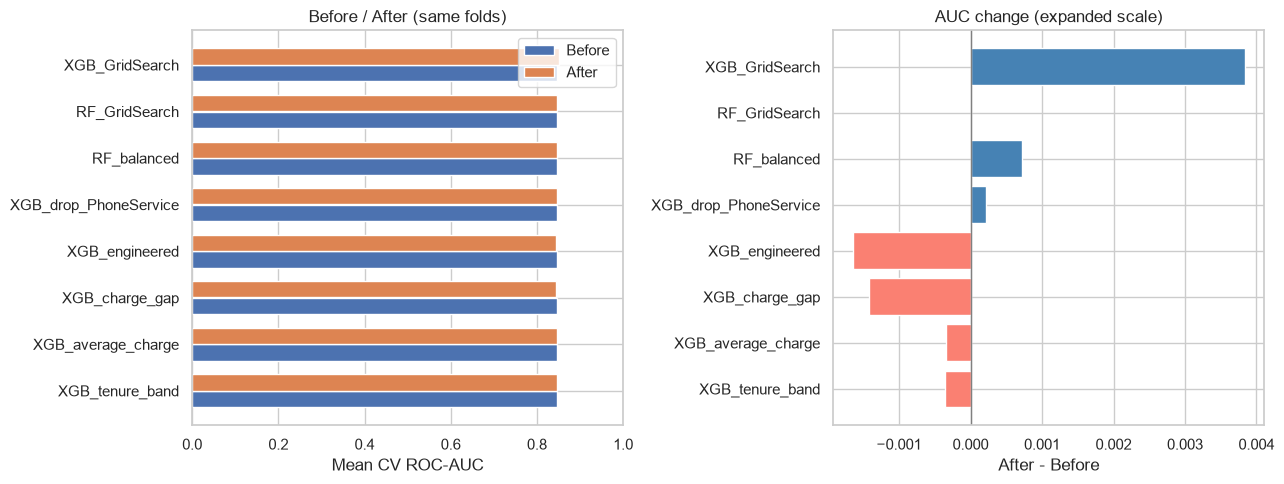

In [21]:
experiment_plan = [
    ('가입 기간 구간 추가', 'XGBoost', 'XGB_tenure_band'),
    ('월평균 누적 요금 추가', 'XGBoost', 'XGB_average_charge'),
    ('현재와 평균 요금 차이 추가', 'XGBoost', 'XGB_charge_gap'),
    ('세 파생변수 함께 추가', 'XGBoost', 'XGB_engineered'),
    ('전화 가입 변수 제거', 'XGBoost', 'XGB_drop_PhoneService'),
    ('클래스 가중치 적용', 'RandomForest', 'RF_balanced'),
    ('RF 설정 자동 튜닝', 'RandomForest', 'RF_GridSearch'),
    ('XGB 설정 자동 튜닝', 'XGBoost', 'XGB_GridSearch'),
]
improvement_rows = []
for experiment, before, after in experiment_plan:
    b, a = cv_table.loc[before], cv_table.loc[after]
    improvement_rows.append({
        'Experiment': experiment, 'Before': before, 'After': after,
        'Before_AUC': b.CV_AUC_mean, 'After_AUC': a.CV_AUC_mean,
        'AUC_change': a.CV_AUC_mean-b.CV_AUC_mean,
        'Recall_change': a.Recall-b.Recall, 'F1_change': a.F1-b.F1,
        'AUC_observation': '평균 증가' if a.CV_AUC_mean>b.CV_AUC_mean else
                           ('평균 감소' if a.CV_AUC_mean<b.CV_AUC_mean else '동일'),
    })
improvement_table = pd.DataFrame(improvement_rows)
# 동일한 CV 조건에서 변경 전후를 비교합니다.
display(improvement_table.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(improvement_table))
axes[0].barh(x-.18, improvement_table.Before_AUC, height=.35, label='Before')
axes[0].barh(x+.18, improvement_table.After_AUC, height=.35, label='After')
axes[0].set_yticks(x, improvement_table.After)
axes[0].set(xlim=(0, 1), xlabel='Mean CV ROC-AUC', title='Before / After (same folds)')
axes[0].legend()
axes[1].barh(x, improvement_table.AUC_change,
    color=['steelblue' if d>=0 else 'salmon' for d in improvement_table.AUC_change])
axes[1].set_yticks(x, improvement_table.After)
axes[1].axvline(0, color='gray', linewidth=1)
axes[1].set(xlabel='After - Before', title='AUC change (expanded scale)')
fig.tight_layout()
plt.show()
plt.close(fig)
for row in improvement_table.itertuples():
    print(f'{row.Experiment}: AUC {row.Before_AUC:.4f} → {row.After_AUC:.4f} '
          f'({row.AUC_change:+.4f}), Recall 변화 {row.Recall_change:+.4f}, '
          f'F1 변화 {row.F1_change:+.4f}')
print('최종 후보:', cv_table.index[0], '/ 선택 기준: 가장 높은 평균 CV ROC-AUC')
print('개별 실험의 이득을 합산할 수는 없습니다. 결합 효과는 별도 실험이 필요합니다.')


**실험 해석:** 파생변수 추가는 이번 조건에서 평균 CV AUC를 높이지 못했다. 클래스 가중치는 이탈 탐지를 늘리는 대신 정밀도를 낮추었다. RF 자동 탐색은 기준 설정을 선택했으며 XGBoost 자동 탐색은 더 높은 평균 CV AUC를 보였다. 개별 실험의 개선량은 합산할 수 없으며 결합 효과는 별도 검증이 필요하다.


테스트 평가 전에 확정한 후보: XGB_GridSearch


,max_depth,n_estimators,CV_AUC_mean,CV_AUC_std
0,2,150,0.8496,0.0102
1,2,300,0.8493,0.0088
2,3,150,0.8497,0.0092
3,3,300,0.8464,0.0082


,Variant,Accuracy,Precision,Recall,F1,ROC-AUC,AP,CV_AUC_mean,CV_AUC_std,AUC_change_from_baseline
Model,,,,,,,,,,
XGBoost,original,0.8009,0.6574,0.5211,0.5813,0.8456,0.6610,0.8464,0.0082,0.0000
XGB_drop_PhoneService,drop_phone,0.7991,0.6524,0.5197,0.5786,0.8458,0.6600,0.8466,0.0083,0.0002
XGB_tenure_band,tenure_band,0.8007,0.6571,0.5204,0.5808,0.8453,0.6596,0.8461,0.0082,-0.0004
XGB_average_charge,average_charge,0.7993,0.6522,0.5217,0.5797,0.8454,0.6574,0.8461,0.0073,-0.0003
XGB_charge_gap,charge_gap,0.8033,0.6647,0.5224,0.5850,0.8443,0.6544,0.8450,0.0088,-0.0014
XGB_engineered,engineered,0.8012,0.6615,0.5137,0.5783,0.8440,0.6508,0.8448,0.0089,-0.0016


,tenure,TotalCharges,MonthlyCharges,TenureBand,AvgChargePerMonth,ChargeGap
3738,35,1701.65,49.20,25-48,48.618571,0.581429
3151,15,1151.55,75.10,13-24,76.770000,-1.670000
4860,13,590.35,40.55,13-24,45.411538,-4.861538
3867,26,1905.70,73.50,25-48,73.296154,0.203846
3810,1,44.55,44.55,0-12,44.550000,0.000000


,Variant,Accuracy,Precision,Recall,F1,ROC-AUC,AP,CV_AUC_mean,CV_AUC_std
Model,,,,,,,,,
XGB_GridSearch,original,0.8081,0.6791,0.5251,0.5922,0.8494,0.6658,0.8503,0.0105
XGB_depth3_trees150,original,0.8037,0.6670,0.5197,0.5842,0.8489,0.6633,0.8497,0.0092
XGB_depth2_trees150,original,0.8067,0.6790,0.5151,0.5858,0.8487,0.6637,0.8496,0.0102
XGB_depth2_trees300,original,0.8065,0.6700,0.5338,0.5942,0.8485,0.6653,0.8493,0.0088
RF_balanced,original,0.7570,0.5280,0.7960,0.6348,0.8469,0.6580,0.8476,0.0101
RandomForest,original,0.8001,0.6749,0.4763,0.5584,0.8461,0.6585,0.8469,0.0098
RF_GridSearch,original,0.8001,0.6749,0.4763,0.5584,0.8461,0.6585,0.8469,0.0098
XGB_drop_PhoneService,drop_phone,0.7991,0.6524,0.5197,0.5786,0.8458,0.6600,0.8466,0.0083
XGBoost,original,0.8009,0.6574,0.5211,0.5813,0.8456,0.6610,0.8464,0.0082


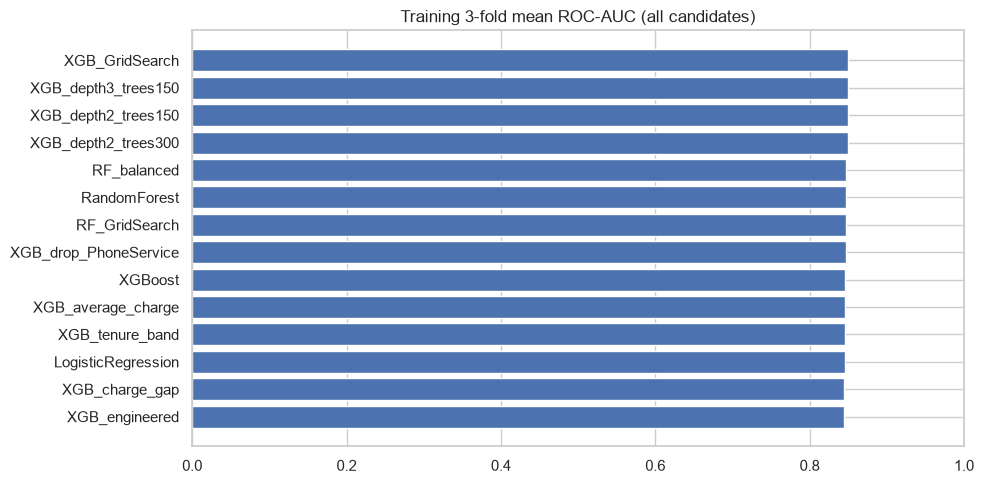

In [22]:
grid_rows=[]
for depth in [2,3]:
    for trees in [150,300]:
        name='XGBoost' if (depth,trees)==(3,300) else f'XGB_depth{depth}_trees{trees}'
        grid_rows.append([depth,trees,cv_table.loc[name,'CV_AUC_mean'],cv_table.loc[name,'CV_AUC_std']])
grid_table=pd.DataFrame(grid_rows,columns=['max_depth','n_estimators','CV_AUC_mean','CV_AUC_std'])
show_table(grid_table.round(4),'xgb_grid_comparison',index=False)
feature_names_to_compare=['XGBoost','XGB_drop_PhoneService','XGB_tenure_band','XGB_average_charge','XGB_charge_gap','XGB_engineered']
feature_comparison=cv_table.loc[feature_names_to_compare].copy()
feature_comparison['AUC_change_from_baseline']=feature_comparison.CV_AUC_mean-cv_table.loc['XGBoost','CV_AUC_mean']
show_table(feature_comparison.round(4),'feature_experiment_comparison')
show_table(make_features(X_train.head(),'engineered')[
    ['tenure','TotalCharges','MonthlyCharges','TenureBand','AvgChargePerMonth','ChargeGap']],
    'engineered_feature_example')
show_table(cv_table.round(4),'all_candidate_cv_scores')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(cv_table.index[::-1],cv_table.CV_AUC_mean.iloc[::-1])
ax.set(title='Training 3-fold mean ROC-AUC (all candidates)',xlim=(0,1))
show_figure('14_candidate_cv_scores',fig)

# 테스트를 보기 전에 선택을 고정합니다.
selected_name=cv_table.index[0]
selection_record={'selected_name':selected_name,'variant':specs[selected_name][0],
    'criterion':'highest mean training 3-fold ROC-AUC','threshold':0.5}
(OUT/'selection_before_test.json').write_text(json.dumps(selection_record,indent=2),encoding='utf-8')
print('테스트 평가 전에 확정한 후보:',selected_name)

**최종 선택:** 평균 CV ROC-AUC가 가장 높은 XGB_GridSearch를 선택한다. 설정은 깊이 2, 나무 300개, 학습률 0.03, L2 규제 5이며 평균 CV AUC는 0.8503이다. 기존 수동 탐색 최고값 0.8497보다 약 0.0006 높다. 테스트 평가 전에 선택 기록을 저장하고 임계값은 0.5로 고정한다.


#### 3.2.4 최종 모델 적용 및 성능 평가
선택된 설정을 학습 80% 전체에 다시 fit하고 테스트 20%를 평가한다. 기준 모델의 테스트 성능은 설명용 비교이며, 여기서 점수를 보고 모델을 다시 선택하지 않는다.

In [23]:
def final_evaluation(X_train, X_test, y_train, y_test, specs, table, out):
    """Lock selection on CV before examining any test outcome."""
    out = Path(out)
    selected_name = table.index[0]
    variant, model = specs[selected_name]
    X_fit = make_features(X_train, variant)
    selected = make_pipeline(X_fit, clone(model)).fit(X_fit, y_train)
    final_prob = selected.predict_proba(make_features(X_test, variant))[:, 1]
    fitted, test_rows, predictions = {}, [], {}
    for name in [*baseline_models(), 'Selected']:
        if name == 'Selected':
            pipeline, probability = selected, final_prob
        else:
            pipeline = make_pipeline(X_train, clone(specs[name][1])).fit(X_train, y_train)
            probability = pipeline.predict_proba(X_test)[:, 1]
        fitted[name] = pipeline
        predictions[name] = probability
        test_rows.append(dict(Model=name, **metric_scores(y_test, probability)))
    test = pd.DataFrame(test_rows).set_index('Model')
    test.to_csv(out / 'test_metrics.csv', encoding='utf-8-sig')
    pd.DataFrame(predictions, index=X_test.index).assign(Actual=y_test).to_csv(out / 'test_predictions.csv')
    bundle = dict(pipeline=selected, variant=variant, selected_name=selected_name,
        input_columns=X_train.columns.tolist(), threshold=0.5)
    joblib.dump(bundle, out / 'selected_model.joblib')
    restored = joblib.load(out / 'selected_model.joblib')
    reload_prob = restored['pipeline'].predict_proba(make_features(X_test, restored['variant']))[:, 1]
    np.testing.assert_allclose(final_prob, reload_prob, rtol=0, atol=0)
    example = X_test.iloc[[0]]
    summary = dict(selected_name=selected_name, selected_variant=variant,
        selection_criterion='highest mean training 3-fold ROC-AUC',
        best_cv_auc=float(table.iloc[0]['CV_AUC_mean']), threshold=0.5,
        train_rows=len(X_train), test_rows=len(X_test), train_churn=int(y_train.sum()),
        test_churn=int(y_test.sum()), train_missing_total=int(X_train['TotalCharges'].isna().sum()),
        transformed_features=len(selected.named_steps['preprocessor'].get_feature_names_out()),
        confusion_matrix=confusion_matrix(y_test, final_prob >= 0.5, labels=[0, 1]).tolist(),
        reloaded_predictions_identical=True,
        example=dict(row_index=int(example.index[0]), tenure=int(example.iloc[0]['tenure']),
            contract=example.iloc[0]['Contract'], monthly_charges=float(example.iloc[0]['MonthlyCharges']),
            probability=float(final_prob[0]), prediction=int(final_prob[0] >= 0.5)))
    (out / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    return test, fitted, summary
assert selected_name==selection_record['selected_name']
test_table,fitted,summary=final_evaluation(X_train,X_test,y_train,y_test,specs,cv_table,OUT)
assert summary['selected_name']==selection_record['selected_name']
show_table(test_table.round(4),'final_test_metrics')
print('Selected =',summary['selected_name'])
print('모두 유지로 예측할 때 테스트 정확도:',f'{(y_test==0).mean():.2%}')
predictions=pd.read_csv(OUT/'test_predictions.csv',index_col=0)
np.testing.assert_array_equal(predictions.index,X_test.index)
selected_prediction=(predictions['Selected']>=.5).astype(int)
report=pd.DataFrame(classification_report(y_test,selected_prediction,
    labels=[0,1],target_names=['Stay 0','Churn 1'],output_dict=True,zero_division=0)).T
show_table(report,'selected_classification_report')
tn,fp,fn_count,tp=confusion_matrix(y_test,selected_prediction,labels=[0,1]).ravel()
counts=pd.DataFrame({'고객 수':[int(tn),int(fp),int(fn_count),int(tp)]},
    index=['TN 유지 정분류','FP 유지를 이탈로 오분류','FN 실제 이탈을 놓침','TP 이탈 탐지'])
show_table(counts,'selected_confusion_counts')
print(f'실제 이탈 {tp+fn_count}명 중 {tp}명 탐지, {fn_count}명 놓침')
print(f'Precision = {tp}/{tp+fp} = {tp/(tp+fp):.2%}')
print(f'Recall = {tp}/{tp+fn_count} = {tp/(tp+fn_count):.2%}')

Selected = XGB_GridSearch
모두 유지로 예측할 때 테스트 정확도: 73.46%
실제 이탈 374명 중 191명 탐지, 183명 놓침
Precision = 191/290 = 65.86%
Recall = 191/374 = 51.07%


,Accuracy,Precision,Recall,F1,ROC-AUC,AP
Model,,,,,,
LogisticRegression,0.8055,0.6572,0.5588,0.6040,0.8421,0.6346
RandomForest,0.8041,0.6801,0.4947,0.5728,0.8452,0.6605
XGBoost,0.8041,0.6633,0.5321,0.5905,0.8450,0.6641
Selected,0.7999,0.6586,0.5107,0.5753,0.8473,0.6644


,precision,recall,f1-score,support
Stay 0,0.836461,0.904348,0.869081,1035.000000
Churn 1,0.658621,0.510695,0.575301,374.000000
accuracy,0.799858,0.799858,0.799858,0.799858
macro avg,0.747541,0.707522,0.722191,1409.000000
weighted avg,0.789256,0.799858,0.791101,1409.000000


,고객 수
TN 유지 정분류,936
FP 유지를 이탈로 오분류,99
FN 실제 이탈을 놓침,183
TP 이탈 탐지,191


**평가 지표**

| 지표 | 의미 |
|---|---|
| Accuracy | 전체 고객 중 정분류 비율 |
| Precision | 이탈 예측 고객 중 실제 이탈 비율 |
| Recall | 실제 이탈 고객 중 탐지 비율 |
| F1 | 정밀도와 재현율의 조화평균 |
| ROC-AUC | 임계값 전반의 이탈·유지 구분 능력 |
| AP | Precision–Recall 곡선의 요약 지표 |

분류 보고서의 Churn 1은 이탈 고객 성능이며 support는 실제 고객 수다. ROC-AUC 0.85는 정확도 85%를 의미하지 않는다.


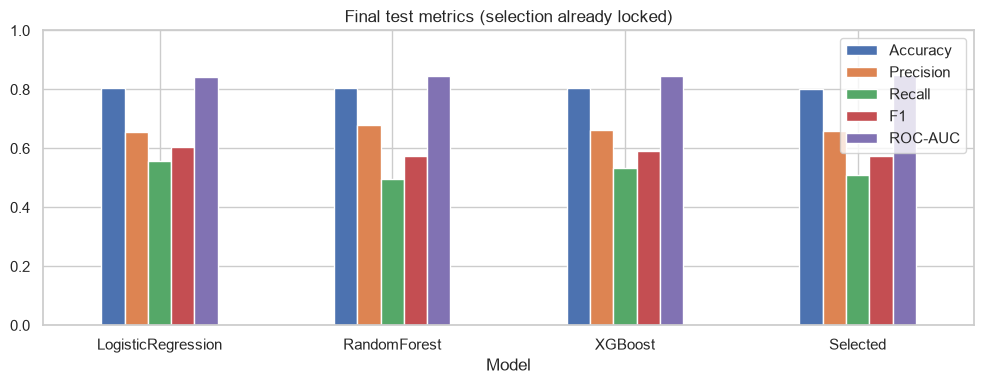

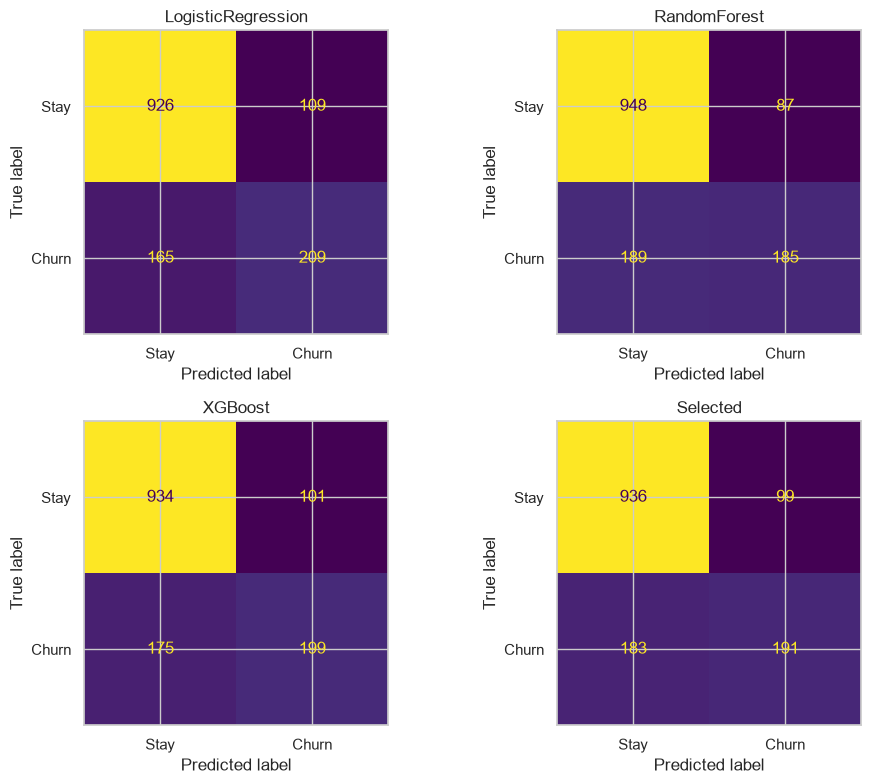

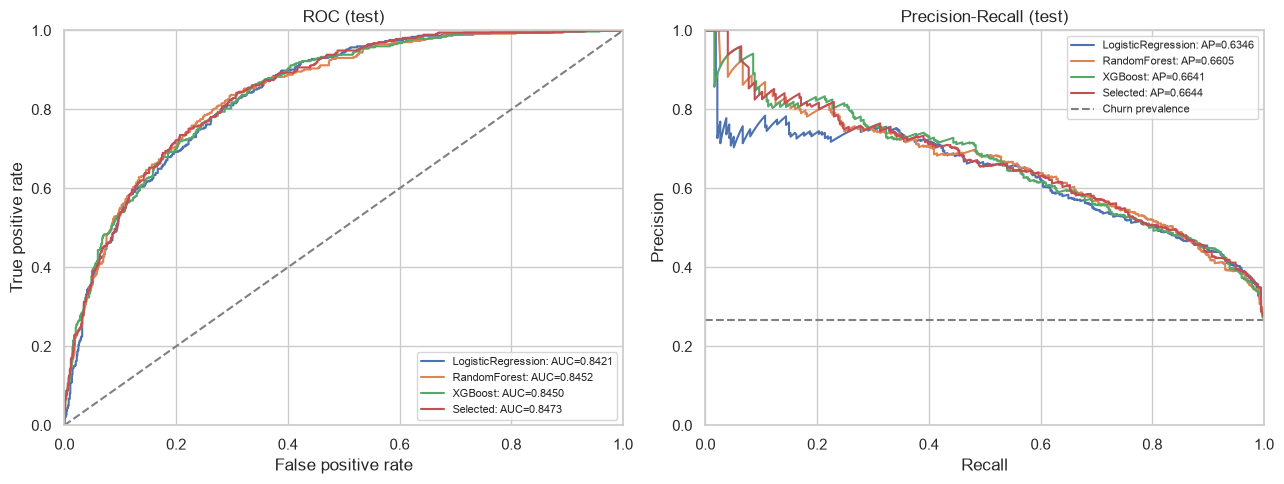

In [24]:
fig,ax=plt.subplots(figsize=(10,4))
test_table[['Accuracy','Precision','Recall','F1','ROC-AUC']].plot.bar(ax=ax,rot=0,ylim=(0,1))
ax.set_title('Final test metrics (selection already locked)')
show_figure('15_final_test_comparison',fig)
fig,axes=plt.subplots(2,2,figsize=(10,8))
for ax,name in zip(axes.ravel(),fitted):
    ConfusionMatrixDisplay.from_predictions(y_test,predictions[name]>=.5,
        labels=[0,1],display_labels=['Stay','Churn'],ax=ax,colorbar=False)
    ax.set_title(name)
show_figure('16_confusion_matrices',fig)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name in fitted:
    fpr,tpr,_=roc_curve(y_test,predictions[name])
    axes[0].plot(fpr,tpr,label=f'{name}: AUC={test_table.loc[name,"ROC-AUC"]:.4f}')
    precision,recall,_=precision_recall_curve(y_test,predictions[name])
    axes[1].plot(recall,precision,label=f'{name}: AP={test_table.loc[name,"AP"]:.4f}')
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[1].axhline(y_test.mean(),linestyle='--',color='gray',label='Churn prevalence')
axes[0].set(title='ROC (test)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1))
axes[1].set(title='Precision-Recall (test)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1))
for ax in axes:ax.legend(fontsize=8)
show_figure('17_roc_and_precision_recall',fig)

**최종 테스트 결과:** 선택 모델의 정확도는 79.99%, 정밀도 65.86%, 재현율 51.07%, F1 0.5753, ROC-AUC 0.8473, AP 0.6644이다. 실제 이탈 374명 중 191명을 찾고 183명을 놓쳤다. 이탈 예측 290명 중 191명이 실제 이탈이다.

혼동행렬은 실제 유지 936명 정분류(TN), 99명 오탐(FP), 실제 이탈 183명 누락(FN), 191명 탐지(TP)로 구성된다.

ROC는 FPR과 TPR의 관계이고 왼쪽 위에 가까울수록 유리하다. 대각선은 무작위 구분 기준선이다. PR은 재현율과 정밀도의 관계이며 수평선은 실제 이탈 비율 약 26.54%다. 임계값을 낮추면 탐지가 증가하는 대신 오탐도 늘 수 있다.

선택 모델은 비교 모델 중 테스트 AUC가 가장 높았지만 재현율·F1은 로지스틱 회귀가 더 높았다. 이전 선택 모델보다 AUC는 소폭 높고 재현율·F1은 낮아, 모든 지표가 개선된 것은 아니다. 테스트는 같은 분할을 재사용하여 완전히 새로운 독립 검증에 해당하지 않는다.


### 3.3 Permutation Importance 및 피처 실험 해석
다음 순열 중요도는 **기준 XGBoost의 학습 내부 CV 검증 폴드**에서 계산한 것이다. 최종 튜닝 모델의 테스트 순열 중요도가 아니다. 표의 Mean은 AUC 감소량, Std는 3개 폴드×3회 섞기의 산포다.

,Feature,Mean,Std
14,Contract,0.0578,0.0056
4,tenure,0.0488,0.0068
7,InternetService,0.0189,0.0038
18,TotalCharges,0.0131,0.0037
17,MonthlyCharges,0.0099,0.0044
10,DeviceProtection,0.0065,0.0016
16,PaymentMethod,0.0048,0.0019
15,PaperlessBilling,0.0040,0.0012
11,TechSupport,0.0034,0.0017
8,OnlineSecurity,0.0028,0.0013


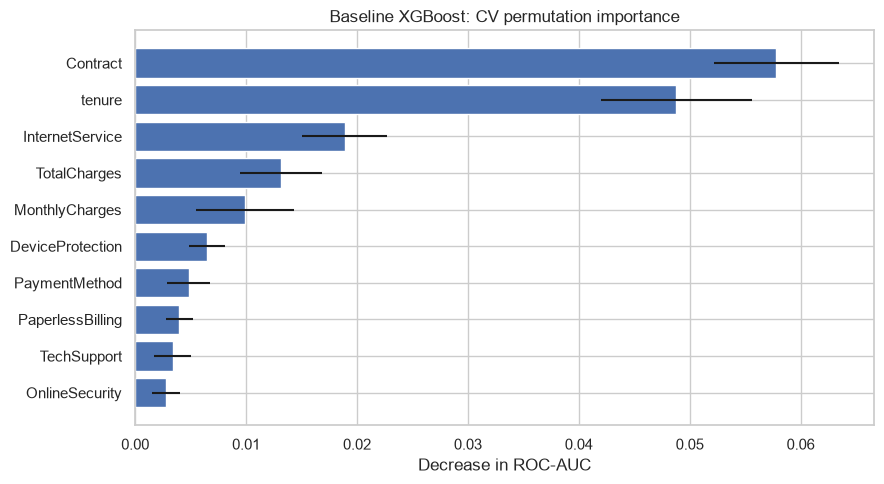

,EncodedFeature,Importance
8,categorical__InternetService_Fiber optic,0.170527
19,categorical__PaymentMethod_Electronic check,0.147471
4,categorical__Contract_Two year,0.136156
3,categorical__Contract_One year,0.103393
6,categorical__DeviceProtection_No internet service,0.059114
0,numeric__tenure,0.055663
9,categorical__InternetService_No,0.054768
12,categorical__OnlineBackup_No internet service,0.039470
2,numeric__TotalCharges,0.035496
16,categorical__PaperlessBilling_Yes,0.033105


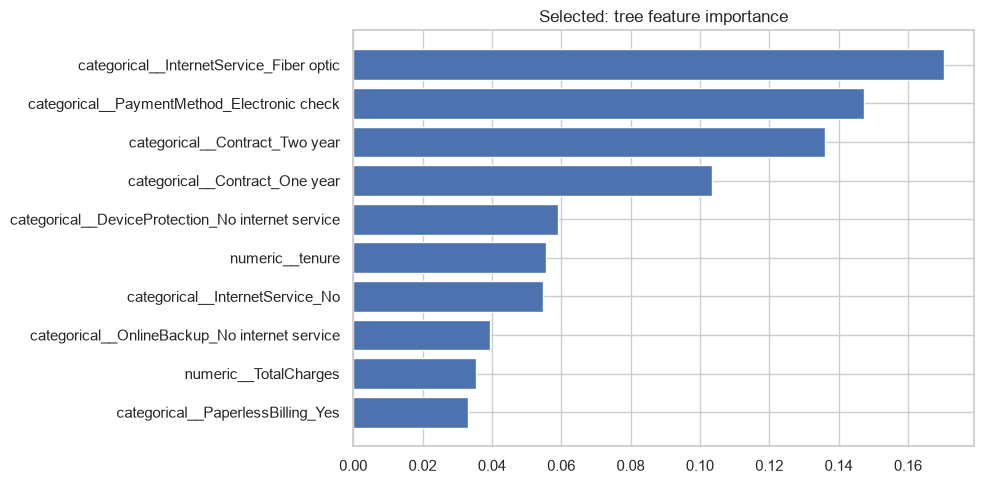

In [25]:
show_table(permutation.round(4),'baseline_cv_permutation_importance',index=False)
top=permutation.head(10).sort_values('Mean')
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(top.Feature,top.Mean,xerr=top.Std)
ax.set(title='Baseline XGBoost: CV permutation importance',xlabel='Decrease in ROC-AUC')
show_figure('18_cv_permutation_importance',fig)

selected=fitted['Selected']
prep=selected.named_steps['preprocessor']
model=selected.named_steps['model']
names=prep.get_feature_names_out()
values=model.feature_importances_ if hasattr(model,'feature_importances_') else np.abs(model.coef_[0])
importance_table=pd.DataFrame({'EncodedFeature':names,'Importance':values}).sort_values('Importance',ascending=False)
show_table(importance_table,'selected_encoded_feature_importance',index=False)
top=importance_table.head(10).sort_values('Importance')
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(top.EncodedFeature,top.Importance)
kind='tree feature importance' if hasattr(model,'feature_importances_') else 'absolute standardized coefficients'
ax.set_title('Selected: '+kind)
show_figure('19_selected_feature_importance',fig)

**중요도 해석:** 순열 중요도는 원본 변수 값을 섞었을 때 ROC-AUC가 감소한 정도다. 기준 XGBoost의 CV 검증 폴드에서 계약·가입 기간·인터넷 서비스 순으로 높았다. 오차 막대는 반복·폴드 결과의 표준편차이며 신뢰구간이 아니다. 감소량 0.0578은 이탈률 감소가 아니라 AUC 감소량이다.

최종 XGBoost 내부 중요도는 gain 기준이며 해당 피처로 나눈 분기가 학습 목적함수를 개선한 정도에 기반한다. 원핫 인코딩으로 범주별 이름이 생성된다. 광인터넷 이용 여부·전자수표 결제·계약 유형 등이 상위다.

두 그래프는 대상 모델과 계산 방식이 달라 순위와 단위가 일치하지 않을 수 있다. 중요도는 영향 방향, 실제 해지 사유, 인과효과를 입증하지 않는다.


### 3.4 고객 이탈 점수 활용 방안
이탈 점수는 상담 우선순위 검토의 참고 자료다. 실제 운영에는 접촉 비용·상담 가능 인원·놓친 이탈의 비용을 정의한 검증이 필요하다. 월 요금만으로 미래 잔존 가치나 실제 손실을 산정할 수는 없다.

## 4. 프로토타이핑
### 4.1 저장 모델 재로딩 및 직접 입력 예측
19개 고객 입력을 받아 같은 전처리와 모델을 적용한다. 저장 객체에는 Pipeline, 피처 변형 방식, 입력 열 목록, 임계값이 포함된다. customerID와 Churn은 입력하지 않는다.


In [26]:
bundle=joblib.load(OUT/'selected_model.joblib')
reload_probability=bundle['pipeline'].predict_proba(make_features(X_test,bundle['variant']))[:,1]
original_probability=fitted['Selected'].predict_proba(make_features(X_test,bundle['variant']))[:,1]
np.testing.assert_allclose(reload_probability,original_probability,rtol=0,atol=0)
print('저장·재로딩 전후 테스트 확률 일치: 확인')

customer_input = {
    'gender':'Female', 'SeniorCitizen':'0', 'Partner':'Yes', 'Dependents':'No',
    'tenure':12, 'PhoneService':'Yes', 'MultipleLines':'No', 'InternetService':'DSL',
    'OnlineSecurity':'No', 'OnlineBackup':'Yes', 'DeviceProtection':'No',
    'TechSupport':'No', 'StreamingTV':'No', 'StreamingMovies':'No',
    'Contract':'Month-to-month', 'PaperlessBilling':'Yes',
    'PaymentMethod':'Electronic check', 'MonthlyCharges':55.0, 'TotalCharges':660.0,
}

def predict_customer(customer_input):
    expected=bundle['input_columns']
    missing=set(expected)-set(customer_input)
    extra=set(customer_input)-set(expected)
    if missing or extra:
        raise ValueError(f'누락 입력: {sorted(missing)}, 불필요 입력: {sorted(extra)}')
    customer=pd.DataFrame([customer_input],columns=expected)
    customer['SeniorCitizen']=customer['SeniorCitizen'].astype(str)
    for col in num_cols:
        customer[col]=pd.to_numeric(customer[col],errors='raise')
        value=customer.iloc[0][col]
        if pd.isna(value) and col!='TotalCharges':
            raise ValueError(f'{col}은 입력이 필요합니다.')
        if pd.notna(value) and (not np.isfinite(value) or value<0):
            raise ValueError(f'{col}은 음수가 아닌 유한한 값이어야 합니다.')
    if customer.iloc[0]['tenure']%1!=0:
        raise ValueError('tenure는 개월 수 정수로 입력하세요.')
    for col in categorical_columns:
        if customer.iloc[0][col] not in set(X_train[col].dropna()):
            raise ValueError(f'{col}: 학습에 있는 범주 {sorted(X_train[col].dropna().unique())} 중에서 입력하세요.')
    if customer.iloc[0]['PhoneService']=='No' and customer.iloc[0]['MultipleLines']!='No phone service':
        raise ValueError('전화 미가입이면 MultipleLines도 No phone service로 입력하세요.')
    if customer.iloc[0]['PhoneService']=='Yes' and customer.iloc[0]['MultipleLines']=='No phone service':
        raise ValueError('전화 가입이면 MultipleLines는 Yes 또는 No로 입력하세요.')
    internet_cols=['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
    no_internet=customer.iloc[0]['InternetService']=='No'
    for col in internet_cols:
        if (customer.iloc[0][col]=='No internet service')!=no_internet:
            raise ValueError('인터넷 가입 여부와 부가서비스의 No internet service 값을 일치시키세요.')
    transformed_customer=make_features(customer,bundle['variant'])
    score=float(bundle['pipeline'].predict_proba(transformed_customer)[0,1])
    result=pd.DataFrame({'이탈 점수':[score],'분류 임계값':[bundle['threshold']],
        '판정':['이탈' if score>=bundle['threshold'] else '유지']})
    return customer,result

customer,result=predict_customer(customer_input)
display(customer.T.rename(columns={0:'입력값'}))
show_table(result,'prototype_prediction',index=False)

저장·재로딩 전후 테스트 확률 일치: 확인


,입력값
gender,Female
SeniorCitizen,0
Partner,Yes
Dependents,No
tenure,12
PhoneService,Yes
MultipleLines,No
InternetService,DSL
OnlineSecurity,No
OnlineBackup,Yes


,이탈 점수,분류 임계값,판정
0,0.319324,0.5,유지


**프로토타입 검증:** 저장 전후 테스트 예측 확률이 정확히 일치하는지 확인한다. 이는 저장·복원 기능의 검증이며 새로운 일반화 성능 평가가 아니다. 예시 입력의 점수는 약 0.319324로 임계값 0.5보다 낮아 유지로 분류된다. 임의 입력이므로 정답 일치 사례나 특정 미래 기간의 보정된 실제 이탈 확률로 해석하지 않는다.


### 4.2 모델 결과 확인
CV 비교표, 최종 성능표, 혼동행렬, ROC·PR 곡선, 중요도를 함께 확인한다. 예측 시연은 노트북 기반이며 별도 웹 서비스는 구현하지 않았다.

## 5. 결론 및 향후 과제
### 5.1 모델 개발 결과 요약
기준 모델과 개선 후보를 같은 CV 조건에서 비교하였다. 파생변수는 최종 입력에 채택하지 않았으며 GridSearchCV로 설정한 XGBoost를 평균 CV ROC-AUC 기준으로 선택하였다. 최종 결과와 탐지·누락 고객 수는 다음 출력과 같다.


In [27]:
s=test_table.loc['Selected']
best_cv=float(cv_table.loc[selected_name,'CV_AUC_mean'])
print(f'학습 {len(X_train):,}명 / 테스트 {len(X_test):,}명')
print('학습 내부 CV로 선택한 후보:',selected_name)
print(f'CV 평균 ROC-AUC: {best_cv:.4f}')
print(f'테스트 Accuracy {s.Accuracy:.2%}, Precision {s.Precision:.2%}, Recall {s.Recall:.2%}, F1 {s.F1:.4f}, ROC-AUC {s["ROC-AUC"]:.4f}, AP {s.AP:.4f}')
print(f'실제 이탈 {tp+fn_count}명 중 {tp}명 탐지, {fn_count}명 놓침')
print('테스트 Recall이 가장 높은 모델:',test_table.Recall.idxmax())
print('테스트 F1이 가장 높은 모델:',test_table.F1.idxmax())
print('PhoneService 제거 CV AUC 변화:',f'{cv_table.loc["XGB_drop_PhoneService","CV_AUC_mean"]-cv_table.loc["XGBoost","CV_AUC_mean"]:+.4f}')
print('파생변수 추가 CV AUC 변화:',f'{cv_table.loc["XGB_engineered","CV_AUC_mean"]-cv_table.loc["XGBoost","CV_AUC_mean"]:+.4f}')
print('최종 원본 입력 수:',len(bundle['input_columns']),'/ 변환 후 피처 수:',len(prep.get_feature_names_out()))
metadata=dict(python=platform.python_version(),pandas=pd.__version__,sklearn=sklearn.__version__,
    xgboost=xgboost.__version__,csv_sha256=hashlib.sha256(CSV_PATH.read_bytes()).hexdigest(),
    random_state=SEED,test_size=.2,cv_splits=N_SPLITS,
    note='Same holdout as previous experiments; not a new independent external validation.')
_ = (OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('\n개선 실험 요약 (동일 CV 기준)')
display(improvement_table.round(4))
print('추가 실험은 AUC·재현율·정밀도·F1의 변화와 한계를 함께 평가한다.')


학습 5,634명 / 테스트 1,409명
학습 내부 CV로 선택한 후보: XGB_GridSearch
CV 평균 ROC-AUC: 0.8503
테스트 Accuracy 79.99%, Precision 65.86%, Recall 51.07%, F1 0.5753, ROC-AUC 0.8473, AP 0.6644
실제 이탈 374명 중 191명 탐지, 183명 놓침
테스트 Recall이 가장 높은 모델: LogisticRegression
테스트 F1이 가장 높은 모델: LogisticRegression
PhoneService 제거 CV AUC 변화: +0.0002
파생변수 추가 CV AUC 변화: -0.0016
최종 원본 입력 수: 19 / 변환 후 피처 수: 30

개선 실험 요약 (동일 CV 기준)
추가 실험은 AUC·재현율·정밀도·F1의 변화와 한계를 함께 평가한다.


,Experiment,Before,After,Before_AUC,After_AUC,AUC_change,Recall_change,F1_change,AUC_observation
0,가입 기간 구간 추가,XGBoost,XGB_tenure_band,0.8464,0.8461,-0.0004,-0.0007,-0.0005,평균 감소
1,월평균 누적 요금 추가,XGBoost,XGB_average_charge,0.8464,0.8461,-0.0003,0.0007,-0.0016,평균 감소
2,현재와 평균 요금 차이 추가,XGBoost,XGB_charge_gap,0.8464,0.8450,-0.0014,0.0013,0.0037,평균 감소
3,세 파생변수 함께 추가,XGBoost,XGB_engineered,0.8464,0.8448,-0.0016,-0.0074,-0.0030,평균 감소
4,전화 가입 변수 제거,XGBoost,XGB_drop_PhoneService,0.8464,0.8466,0.0002,-0.0013,-0.0028,평균 증가
5,클래스 가중치 적용,RandomForest,RF_balanced,0.8469,0.8476,0.0007,0.3197,0.0764,평균 증가
6,RF 설정 자동 튜닝,RandomForest,RF_GridSearch,0.8469,0.8469,0.0000,0.0000,0.0000,동일
7,XGB 설정 자동 튜닝,XGBoost,XGB_GridSearch,0.8464,0.8503,0.0038,0.0040,0.0109,평균 증가


### 5.2 데이터 처리와 실험에서 확인한 사항

| 확인한 사항 | 처리 및 판단 |
|---|---|
| TotalCharges 공백 | 숫자 변환 후 결측 확인, 학습 폴드 중앙값 대체 |
| 평가 데이터 누수 가능성 | 80:20 분할과 폴드 내부 전처리 |
| 모델별 우수 지표 차이 | CV AUC 선택 기준과 Recall·F1 장단점 구분 |
| 파생변수 추가의 성능 감소 | 개별·통합 비교 후 최종 미채택 |
| 불균형 가중치의 장단점 | OOF 재현율 증가와 정밀도 감소 확인 |

### 5.3 한계점과 향후 과제
- 같은 CV로 여러 후보를 선택하여 최고 점수에 선택 편향이 있을 수 있다.
- 이전 실험과 같은 테스트를 재사용하여 새로운 독립 평가가 아니다. 외부·시간 기준 자료에서 추가 검증이 필요하다.
- 임계값 0.5에서 실제 이탈 고객의 약 절반을 놓쳤다. 후속 실험은 업무 비용과 상담 가능 인원을 반영한 임계값 검토가 필요하다.
- 클래스 가중치는 이미 비교했으며 SMOTE·확률 보정·정책 효과 검증은 수행하지 않았다.
- 관찰된 연관성과 중요도는 실제 해지 원인이나 유지 정책의 인과효과를 입증하지 않는다.

**산출물:** 그림과 표는 `outputs_80_20/notebook_figures`, `outputs_80_20/notebook_tables`, CV·테스트 결과와 저장 모델은 `outputs_80_20`에 저장된다.
